In [1]:
!pip install -q pandas matplotlib seaborn numpy

In [2]:
## 📋 COMPLETE ANALYSIS PIPELINE: Linguistic Markers + Token Usage + Model Rankings

### 📑 Table of Contents
**SECTION 1: Setup & Data Processing**
- Cell 3: Dependencies
- Cell 4: Data Loading
- Cell 5: Data Preprocessing (Personas, Gender, Type mapping)
- Cell 5 (REVISED): Marker Extraction — 5-group taxonomy, 20 sub-markers, backward-compatible
- Cell 6: Analisis Statistik Multi-Dimensitegories + density normalization)
- Cell 7: Multi-dimensional Statistical Aggregation

**SECTION 2: Linguistic Analysis & Visualizations**
- Cell 8: Comprehensive Visualizations (Heatmaps, Radar, Boxplot, Barplot)
- Cell 9: Persona Grouping Functions (5-group & 3-group aggregation)
- Cell 10: Radar Chart - 5-Group Persona Setup
- Cell 11: Radar Chart - 3-Group Gender Setup
- Cell 12: Summary Statistics & CSV Export

**SECTION 3: Token Usage Analysis**
- Cell 13: Header & Introduction
- Cell 14: Token Data Aggregation by Persona Groups
- Cell 15: Token Usage Bar Chart Visualizations

**SECTION 4: Model Rankings & Performance**
- Cell 16: Header & Introduction
- Cell 17: Model Rankings by Marker Category (Ranked Tables)
- Cell 18: Model Rankings - Bar Chart Visualizations (Horizontal/Vertical/Grouped)

---
### 📊 Datasets Generated Throughout Pipeline:
1. **comprehensive_linguistic_bias_report.csv** - Multi-dimensional marker statistics
2. **aggregated_5_groups_markers.csv** - 5-group persona aggregation
3. **aggregated_3_groups_markers.csv** - 3-group gender aggregation
4. **token_usage_5_groups.csv** - Token metrics by 5-group personas
5. **token_usage_3_groups.csv** - Token metrics by 3-group genders

### ✨ Key Features:
- **13 Linguistic Markers**: Sequential, Instructional, Structural, Logical, Formal Logic, Verification, Hedging, Boosters, Technical, Self-mentions, Engagement, Attitude, Clarification
- **12 LLM Models**: Analyzed across 9 personas (3 gender × explicit/implicit + neutral)
- **Dual Visualization**: 5-group (explicit/implicit granularity) + 3-group (gender comparison)
- **Token Analysis**: Correlate linguistic patterns with output verbosity
- **Model Ranking**: Compare models by marker usage patterns

---

SyntaxError: invalid character '—' (U+2014) (1339856481.py, line 8)

# Fine-Grained Linguistic Marker Analysis (9 Persona x 12 Model)
Analisis ini menjaga granularitas `persona_folder` (9 kategori asli) tanpa agregasi dini.
Perbandingan utama dilakukan pada `is_correct=True` vs `is_correct=False` untuk melihat perubahan perilaku model saat benar dan saat salah.

In [4]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

DATA_PATH = Path(r"E:\Tugas Akhir\TugasAkhir\result\reports\all_results_gsm8k_lite.csv")
OUTPUT_REPORT_PATH = Path("comprehensive_linguistic_bias_report.csv")

candidate_paths = [
    DATA_PATH,
    Path(r"D:\TugasAkhir\result\reports\all_results_gsm8k_lite.csv"),
    Path(r"D:\Tugas Akhir\TugasAkhir\result\reports\all_results_gsm8k_lite.csv"),
]

for path in candidate_paths:
    if path.exists():
        df = pd.read_csv(path)
        DATA_PATH = path
        break
else:
    raise FileNotFoundError(
        f"CSV file not found. Checked: {[str(p) for p in candidate_paths]}"
    )
print(f"Loaded rows: {len(df):,} | columns: {len(df.columns)}")
df.head(2)

Loaded rows: 149,483 | columns: 9


C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\1723277416.py:22: DtypeWarning: Columns (0: is_correct) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


,model,persona,question_id,dataset,ground_truth,ground_truth_answer,response_content,extracted_answer,is_correct
0,allenai_olmo-3-32b-think,man_explicit_1,0.0,gsm8k_test,Janet sells 16 - 3 - 4 = <<16-3-4=9>>9 duck eg...,18.0,Janet's ducks lay 16 eggs daily. She uses 3 eg...,18.0,True
1,allenai_olmo-3-32b-think,man_explicit_1,0.0,gsm8k_test,It takes 2/2=<<2/2=1>>1 bolt of white fiber\r\...,3.0,The robe requires 2 bolts of blue fiber. The w...,3.0,True


In [6]:
# ===== 1) Data Preprocessing (Tanpa Agregasi Dini) =====
required_cols = ["model_name", "persona_folder", "is_correct", "response_content_full"]
missing_required = [c for c in required_cols if c not in df.columns]
if missing_required:
    # try common alternative column names and auto-rename them before erroring
    alt_names = {
        "model": "model_name",
        "persona": "persona_folder",
        "response_content": "response_content_full",
        "response": "response_content_full",
    }
    rename_map = {k: v for k, v in alt_names.items() if k in df.columns and v not in df.columns}
    if rename_map:
        df.rename(columns=rename_map, inplace=True)
        print(f"Auto-renamed columns: {rename_map}")

    missing_required = [c for c in required_cols if c not in df.columns]
    if missing_required:
        raise ValueError(f"Missing required columns: {missing_required}")

persona_order = [
    "man_implicit_1", "man_implicit_2", "man_implicit_3",
    "woman_implicit_1", "woman_implicit_2", "woman_implicit_3",
    "man_explicit_1", "woman_explicit_1", "neutral",
]

def normalize_is_correct(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, bool):
        return value
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "y"}:
        return True
    if text in {"false", "0", "no", "n"}:
        return False
    return np.nan

def map_gender(folder):
    text = str(folder).lower() if pd.notna(folder) else ""
    if "woman" in text or "women" in text:
        return "Woman"
    if "man" in text or "men" in text:
        return "Man"
    return "Neutral"

def map_persona_type(folder):
    text = str(folder).lower() if pd.notna(folder) else ""
    if "implicit" in text:
        return "Implicit"
    if "explicit" in text:
        return "Explicit"
    return "Neutral"

df["response_content_full"] = df["response_content_full"].fillna("").astype(str)
df["is_correct"] = df["is_correct"].apply(normalize_is_correct)
df["gender"] = df["persona_folder"].apply(map_gender)
df["persona_type"] = df["persona_folder"].apply(map_persona_type)

# Pertahankan 9 persona target; tidak menghapus is_correct=False
df = df[df["persona_folder"].isin(persona_order)].copy()
df["persona_folder"] = pd.Categorical(df["persona_folder"], categories=persona_order, ordered=True)

print("Unique persona_folder:", sorted(df["persona_folder"].dropna().unique().tolist()))
print(df["is_correct"].value_counts(dropna=False))
df[["model_name", "persona_folder", "gender", "persona_type", "is_correct"]].head()

Auto-renamed columns: {'model': 'model_name', 'persona': 'persona_folder', 'response_content': 'response_content_full'}
Unique persona_folder: ['man_explicit_1', 'man_implicit_1', 'man_implicit_2', 'man_implicit_3', 'neutral', 'woman_explicit_1', 'woman_implicit_1', 'woman_implicit_2', 'woman_implicit_3']
is_correct
True     129714
False     19707
NaN          56
Name: count, dtype: int64


,model_name,persona_folder,gender,persona_type,is_correct
0,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
1,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
2,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
3,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True
4,allenai_olmo-3-32b-think,man_explicit_1,Man,Explicit,True


# ===== Linguistic Marker Taxonomy — Revised =====
#
# Kelompok      Sub-marker              Operasionalisasi
# ─────────────────────────────────────────────────────────────────────────────
# A. Opening    instructional           Dimulai dengan "let's", "to find", "we need to"
#    Ritual     heres_how               Dimulai dengan "here's how", "okay", "so let"
#    (binary,   scratchpad              Dimulai dengan "hmm", "wait", "<think>", "let me re-read"
#    first 150  answer_first            Angka atau "the answer is" di awal
#    chars)     direct_factual          Langsung menyebut entitas soal ("Janet's ducks…")
#               other                   Tidak cocok dengan pola di atas
#
# B. Reasoning  sequential              Numbered steps + ordinal keywords (first/then/finally)
#    Org.        bullet                  Baris dimulai dengan - * •
#    (density)   section_header          Markdown header (##) atau **Bold:** di awal baris
#               prose_chain_flag        Binary: ada logical kw TAPI tidak ada list → reasoning naratif
#               implicit_consequence    "so she/he/we/it [verb]" — inferensi informal
#
# C. Epistemic  hedging                 maybe/perhaps/might/seems/approximately
#    Stance      boosters               clearly/obviously/definitely/must be/of course
#    (density)   self_correction        wait/actually/let me re-check/i made an error
#               prob_rereading          let me re-read/the problem says/going back to
#               assumption_marking      assuming/given that/note that/as stated
#
# D. Math       latex_display           \[…\] / $$ / \frac / \boxed (formal register)
#    Formatting  inline_arith           3 × 4 = 12 (informal but functional)
#    (density)   boxed_answer           \boxed{…} secara spesifik
#               markdown_heavy          **bold** spans (visual emphasis)
#
# E. Verif.     answer_announce         "the answer is" / "final answer:" / **Answer:**
#    (density)   arith_check            double-check/let me verify/checks out
#               interp_check            makes sense/this confirms/consistent with
#               contradiction           but wait/however this/that can't be right
#
# Normalisasi : density = (raw_count / word_count) × 100  (per 100 kata)
# Pengecualian: opener_type dan prose_chain_flag → tidak dinormalisasi (bukan rate)
# Sumber      : Hyland (2005) untuk hedges/boosters/engagement;
#               Biber (1988) untuk formal_logic/register;
#               Wei et al. (2022) untuk CoT step structure;
#               Park & Lei (2026) untuk logical connectives;
#               Meek et al. (2025) untuk verification/verbosity.


In [7]:
# ===== 2-3) Marker Extraction — Revised ============================================
# Replaces the previous flat-list extraction with a modular, taxonomy-aligned design.
#
# Taxonomy (5 groups, 20 sub-markers → 13 aggregate categories):
#   A. Opening Ritual      — captures HOW a model starts its reasoning
#   B. Reasoning Org.      — captures HOW steps are connected / presented
#   C. Epistemic Stance    — captures model's expressed certainty
#   D. Math Formatting     — captures symbolic/visual conventions
#   E. Verification        — captures self-checking behavior
#
# Normalization: density = (raw_count / word_count) × 100  (per 100 words)
# Opening ritual: binary flag on first 150 chars — not normalized (it's a type, not a rate)
#
# Sources:
#   Hyland (2005) — hedges, boosters, self-mentions, engagement
#   Biber (1988)  — register (formal_logic, passive_math, technical vocab)
#   Wei et al. (2022) — CoT step structure motivation
#   Park & Lei (2026) — logical connectives as high-entropy forking points
# ====================================================================================

import re
import numpy as np


# ── Utility ──────────────────────────────────────────────────────────────────────────

def _count_words(text: str) -> int:
    return len(re.findall(r"\b\w+\b", text)) if isinstance(text, str) else 0

def _count(text: str, pattern: re.Pattern) -> int:
    return len(pattern.findall(text)) if isinstance(text, str) else 0

def _density(score: float, word_count: int) -> float:
    """Raw count → occurrences per 100 words. Returns NaN for empty text."""
    return (score / word_count * 100) if word_count > 0 else np.nan


# ══════════════════════════════════════════════════════════════════════════════════════
# A. OPENING RITUAL  (binary; measured on first 150 characters only)
#    Rationale: the first sentence is the strongest signal of the model's default
#    discourse strategy. Per-model opener signatures are highly consistent
#    (e.g. llama3-8b: 99% instructional; gemma-2-9b: 98% "here's how"),
#    making this a discriminative feature across model families.
#    Confound: long system prompts or multi-turn context may shift the opener.
# ══════════════════════════════════════════════════════════════════════════════════════

_P_OPENER_INSTRUCTIONAL = re.compile(
    r"^(let'?s\b|let us\b|to\s+(find|solve|calculate|determine)\b"
    r"|we\s+need\s+to\b|first,?\s+(let|we)\b|now,?\s+(let|we)\b"
    r"|i\s+need\s+to\s+(find|solve|calculate|figure)\b)",
    re.IGNORECASE,
)
_P_OPENER_HERES_HOW = re.compile(
    r"^(here'?s?\s+(how|the|my|what|a|an)\b|alright[,!]?\s|okay[,!]?\s"
    r"|so,?\s+(let|here|to|we|i)\b|sure[,!]?\s)",
    re.IGNORECASE,
)
_P_OPENER_SCRATCHPAD = re.compile(
    r"^(<think>|hmm\b|wait[,!]?\s|let\s+me\s+(think|re.?read|check|work)"
    r"|i\s+(need|want)\s+to\s+(re.?read|think|figure|work)\b)",
    re.IGNORECASE,
)
_P_OPENER_ANSWER_FIRST = re.compile(
    # Starts immediately with a numeric answer or bold-formatted answer
    r"^(\*{0,2}\$?\d[\d,\.]*\*{0,2}\s*[\.!]|the\s+answer\s+is\b|answer\s*:)",
    re.IGNORECASE,
)
_P_OPENER_DIRECT_FACTUAL = re.compile(
    # Restates a problem entity directly (e.g. "Janet's ducks lay…")
    r"^(janet'?s?\s+\w+|the\s+(problem|question|total|given)\b"
    r"|given\s+(that|the|a)\b|\w+\s+has\s+\d|\w+'?s?\s+(ducks?|eggs?|friends?))",
    re.IGNORECASE,
)

def classify_opener(text: str) -> str:
    """Return the opening ritual type based on first 150 characters."""
    if not isinstance(text, str) or len(text.strip()) == 0:
        return "unknown"
    prefix = text.strip()[:150]
    if _P_OPENER_SCRATCHPAD.search(prefix):
        return "scratchpad"
    if _P_OPENER_ANSWER_FIRST.search(prefix):
        return "answer_first"
    if _P_OPENER_INSTRUCTIONAL.search(prefix):
        return "instructional"
    if _P_OPENER_DIRECT_FACTUAL.search(prefix):
        return "direct_factual"
    if _P_OPENER_HERES_HOW.search(prefix):
        return "heres_how"
    return "other"


# ══════════════════════════════════════════════════════════════════════════════════════
# B. REASONING ORGANIZATION  (count-based → density)
#    Sequential, bullet, section-header, prose-chain, implicit-consequence
#    Rationale: Wei et al. (2022) establish that explicit step enumeration is the
#    canonical CoT form. Variation in organization (prose vs. list vs. header)
#    captures different presentation registers (Biber D1: involved↔informational).
# ══════════════════════════════════════════════════════════════════════════════════════

# B1. Numbered sequential structure — "1. … 2. … Step 1 …"
_P_SEQ_NUM   = re.compile(r"\b\d+[\.)\s]\s+\w", re.IGNORECASE)
_P_SEQ_KW    = re.compile(
    r"\b(first|second|third|fourth|fifth|finally|next|then|afterward|lastly)\b",
    re.IGNORECASE,
)

def score_sequential(text: str) -> int:
    return _count(text, _P_SEQ_NUM) + _count(text, _P_SEQ_KW)

# B2. Bullet hierarchy — dash/asterisk/dot bullets
_P_BULLET    = re.compile(r"(?m)^\s*[-*•]\s+\w", re.IGNORECASE)

def score_bullet(text: str) -> int:
    return _count(text, _P_BULLET)

# B3. Section-header structure — markdown headers or bold colon-labels
#     Confound: bold emphasis inside prose also triggers structural_bold.
#     We restrict to line-initial bold followed by colon to reduce false positives.
_P_HEADER_MD  = re.compile(r"(?m)^#{1,3}\s+\S")
_P_HEADER_BOLD= re.compile(r"(?m)^\*\*[^*\n]{2,40}\*\*\s*[:\-]?\s*$")
_P_COLON_LABEL= re.compile(r"(?m)^\*\*[^*\n]{2,35}:\*\*")

def score_section_header(text: str) -> int:
    return (_count(text, _P_HEADER_MD)
            + _count(text, _P_HEADER_BOLD)
            + _count(text, _P_COLON_LABEL))

# B4. Prose-chain reasoning — no bullets/numbers but uses logical connectives
#     Operationalized as a binary flag (not a count) because it's a global property.
_P_PROSE_LOG  = re.compile(
    r"\b(therefore|thus|hence|which means|this means|this gives(?: us)?|so we)\b",
    re.IGNORECASE,
)
_P_HAS_LIST   = re.compile(r"(?m)(^\s*[-*•]\s+|\b\d+[\.)\s]\s+\w)", re.IGNORECASE)

def is_prose_chain(text: str) -> int:
    """Binary: 1 if response uses logical connectives WITHOUT list structure."""
    if not isinstance(text, str):
        return 0
    return int(bool(_P_PROSE_LOG.search(text)) and not bool(_P_HAS_LIST.search(text)))

# B5. Implicit consequence chaining — "so [subject]"
#     Captures informal connective reasoning ("so she earns", "so we have")
#     Confound: "so" as a standalone filler not followed by a subject.
_P_IMPL_CONS  = re.compile(r"(?<!\w)so\s+(?:she|he|they|it|we|janet|the|this|that)\b", re.IGNORECASE)

def score_implicit_consequence(text: str) -> int:
    return _count(text, _P_IMPL_CONS)

# Aggregate: sequential + bullet combined (overall list-orientation)
def score_list_orientation(text: str) -> int:
    return score_sequential(text) + score_bullet(text)


# ══════════════════════════════════════════════════════════════════════════════════════
# C. EPISTEMIC STANCE  (count-based → density)
#    Hedging, boosters, self-correction, problem re-reading, assumption-marking
#    Rationale: Hyland (2005) establishes hedges/boosters as the primary interactional
#    metadiscourse markers. Park & Lei (2026) show logical connectives are "high
#    entropy forking points" — epistemic markers around these junctions distinguish
#    confident from uncertain reasoning styles.
# ══════════════════════════════════════════════════════════════════════════════════════

_P_HEDGING = re.compile(
    r"\b(maybe|perhaps|might(?!\s+be\s+worth)|could(?!\s+be\s+\d)|seems?|suggests?"
    r"|possibly|tentatively|it\s+appears?|approximately|about|roughly|around)\b",
    re.IGNORECASE,
)
_P_BOOSTERS = re.compile(
    r"\b(clearly|obviously|definitely|must\s+be|always|in\s+fact|absolutely"
    r"|certainly|surely|undoubtedly|of\s+course)\b",
    re.IGNORECASE,
)
_P_SELF_CORRECTION = re.compile(
    r"\b(wait[,!]?|actually[,!]?|let\s+me\s+re.?check|let\s+me\s+re.?calculate"
    r"|i\s+made\s+an\s+error|i\s+was\s+wrong|correction[:\s]|oops|recalculating)\b",
    re.IGNORECASE,
)
_P_PROB_REREADING = re.compile(
    r"\b(let\s+me\s+re.?read|re.?reading\s+the\s+problem|going\s+back\s+to"
    r"|the\s+problem\s+(says?|states?|asks?|mentions?)|re.?visiting)\b",
    re.IGNORECASE,
)
_P_ASSUMPTION = re.compile(
    r"\b(assuming\b|assume\b|given\s+that\b|i'?ll\s+assume|let'?s?\s+assume"
    r"|we\s+assume|note\s+that\b|per\s+the\s+problem|as\s+stated)\b",
    re.IGNORECASE,
)

def score_hedging(text: str) -> int:
    return _count(text, _P_HEDGING)

def score_boosters(text: str) -> int:
    return _count(text, _P_BOOSTERS)

def score_self_correction(text: str) -> int:
    return _count(text, _P_SELF_CORRECTION)

def score_problem_rereading(text: str) -> int:
    return _count(text, _P_PROB_REREADING)

def score_assumption_marking(text: str) -> int:
    return _count(text, _P_ASSUMPTION)


# ══════════════════════════════════════════════════════════════════════════════════════
# D. MATHEMATICAL FORMATTING STYLE  (count-based → density)
#    LaTeX, inline arithmetic, boxed answer, markdown-heavy
#    Rationale: Biber (1988) Dimension 5 (Abstract/Non-abstract) is sensitive to
#    nominalization and passive constructions. LaTeX display and boxed answers are
#    the LLM-native equivalent of formal register in mathematical writing.
#    Confound: some models emit LaTeX by default regardless of persona.
# ══════════════════════════════════════════════════════════════════════════════════════

_P_LATEX_DISPLAY  = re.compile(r"(\\\[|\\\(|\$\$|\\dfrac|\\frac\{|\\text\{|\\boxed\{)", re.IGNORECASE)
_P_INLINE_ARITH   = re.compile(r"\d[\d,\.]*\s*[+\-×x\*÷/]\s*\d[\d,\.]*\s*=\s*\d")
_P_BOXED_ANSWER   = re.compile(r"\\boxed\{[^}]{1,50}\}")
_P_MARKDOWN_HEAVY = re.compile(r"\*\*[^*\n]{1,60}\*\*")  # bold spans

def score_latex_display(text: str) -> int:
    return _count(text, _P_LATEX_DISPLAY)

def score_inline_arithmetic(text: str) -> int:
    return _count(text, _P_INLINE_ARITH)

def score_boxed_answer(text: str) -> int:
    return _count(text, _P_BOXED_ANSWER)

def score_markdown_heavy(text: str) -> int:
    return _count(text, _P_MARKDOWN_HEAVY)

def score_formal_math(text: str) -> int:
    """Aggregate: LaTeX + boxed (formal register)."""
    return score_latex_display(text) + score_boxed_answer(text)

def score_informal_math(text: str) -> int:
    """Aggregate: inline arithmetic (informal but functional)."""
    return score_inline_arithmetic(text)


# ══════════════════════════════════════════════════════════════════════════════════════
# E. VERIFICATION BEHAVIOR  (count-based → density)
#    Arithmetic check, interpretation check, contradiction detection
#    Rationale: Meek et al. (2025) formalize verification as a distinct CoT property.
#    Self-checking under persona pressure may reduce (sycophantic shortcut) or
#    increase (defensive overcorrection) — both are meaningful signals.
# ══════════════════════════════════════════════════════════════════════════════════════

_P_ANSWER_ANNOUNCE = re.compile(
    r"(the\s+answer\s+is\b|\*{0,2}final\s+answer\*{0,2}[:\s]"
    r"|\*{0,2}answer\*{0,2}[:\s]|therefore,?\s+janet\s+makes)",
    re.IGNORECASE,
)
_P_ARITH_CHECK = re.compile(
    r"\b(double.?check|let\s+me\s+(verify|check|confirm)\b|checking\b"
    r"|re.?verif|verify\s+this|that\s+(is\s+)?correct|checks?\s+out)\b",
    re.IGNORECASE,
)
_P_INTERP_CHECK = re.compile(
    r"\b(makes?\s+sense\b|sanity\s+check|this\s+is\s+correct\b"
    r"|this\s+confirms?\b|which\s+confirms?\b|consistent\s+with\b"
    r"|matches?\s+the|this\s+is\s+reasonable)\b",
    re.IGNORECASE,
)
_P_CONTRADICTION = re.compile(
    r"\b(but\s+wait\b|however,?\s+(?:this|that|we|i)\b"
    r"|that\s+can'?t\s+be\b|cannot\s+be\s+right\b"
    r"|that\s+doesn'?t\s+(?:add\s+up|make\s+sense)\b|contradiction\b)\b",
    re.IGNORECASE,
)

def score_answer_announce(text: str) -> int:
    return _count(text, _P_ANSWER_ANNOUNCE)

def score_arith_check(text: str) -> int:
    return _count(text, _P_ARITH_CHECK)

def score_interp_check(text: str) -> int:
    return _count(text, _P_INTERP_CHECK)

def score_contradiction(text: str) -> int:
    return _count(text, _P_CONTRADICTION)

def score_verification(text: str) -> int:
    """Aggregate: all explicit self-checking behaviors."""
    return score_arith_check(text) + score_interp_check(text) + score_contradiction(text)


# ══════════════════════════════════════════════════════════════════════════════════════
# LEGACY COMPATIBILITY — retained from previous version, now computed via new fns
# ══════════════════════════════════════════════════════════════════════════════════════

_P_INSTRUCTIONAL_KW = re.compile(
    r"\b(to\s+find|to\s+calculate|to\s+determine|let'?s|now\s+we|we\s+need\s+to"
    r"|solve\s+for|starting\s+with|first\s+we\s+need)\b",
    re.IGNORECASE,
)
_P_LOGICAL_KW = re.compile(
    r"\b(therefore|thus|hence|consequently|so|because|since"
    r"|implies|results\s+in|it\s+follows\s+that)\b",
    re.IGNORECASE,
)
_P_NARRATIVE_PROSE = re.compile(
    r"\b(which\s+means|this\s+means|this\s+gives(?:\s+us)?|so\s+we|this\s+tells\s+us)\b",
    re.IGNORECASE,
)
_P_SELF_MENTIONS  = re.compile(r"\b(I|we|my|our|me|us)\b", re.IGNORECASE)
_P_ENGAGEMENT     = re.compile(r"\b(you|your|note\s+that|consider|recall|look\s+at|imagine|let\s+us)\b", re.IGNORECASE)
_P_ATTITUDE       = re.compile(r"\b(importantly|unfortunately|correctly|surprisingly|fortunately|interesting|essential|crucial)\b", re.IGNORECASE)
_P_CLARIFICATION  = re.compile(r"\b(in\s+other\s+words|that\s+is|namely|for\s+example|e\.g\.|i\.e\.|such\s+as)\b", re.IGNORECASE)
_P_TECHNICAL_BASE = re.compile(r"\b(specifically|variable|constant|formula|calculate|coefficient|asymptotic|result)\b", re.IGNORECASE)
_P_PASSIVE_MATH   = re.compile(r"\b(is\s+calculated|is\s+given\s+by|can\s+be\s+written|is\s+defined\s+as|was\s+obtained|is\s+multiplied|is\s+divided|is\s+added|is\s+subtracted|can\s+be\s+simplified)\b", re.IGNORECASE)
_P_NOMINALIZATION = re.compile(r"\b(equation|substitution|calculation|addition|subtraction|multiplication|division|fraction|distribution|measurement|evaluation)\b", re.IGNORECASE)


# ══════════════════════════════════════════════════════════════════════════════════════
# MAIN EXTRACTION — apply all markers to df
# ══════════════════════════════════════════════════════════════════════════════════════

TEXT_COL = "response_content_full"

df[TEXT_COL] = df[TEXT_COL].fillna("").astype(str)
df["word_count"] = df[TEXT_COL].apply(_count_words)

# ── A. Opening Ritual (categorical, not density) ──────────────────────────────────
df["opener_type"] = df[TEXT_COL].apply(classify_opener)

# ── B. Reasoning Organization ─────────────────────────────────────────────────────
df["sequential_score"]           = df[TEXT_COL].apply(score_sequential)
df["bullet_score"]               = df[TEXT_COL].apply(score_bullet)
df["section_header_score"]       = df[TEXT_COL].apply(score_section_header)
df["prose_chain_flag"]           = df[TEXT_COL].apply(is_prose_chain)   # binary
df["implicit_consequence_score"] = df[TEXT_COL].apply(score_implicit_consequence)
df["list_orientation_score"]     = df[TEXT_COL].apply(score_list_orientation)

# ── C. Epistemic Stance ───────────────────────────────────────────────────────────
df["hedging_score"]           = df[TEXT_COL].apply(score_hedging)
df["boosters_score"]          = df[TEXT_COL].apply(score_boosters)
df["self_correction_score"]   = df[TEXT_COL].apply(score_self_correction)
df["prob_rereading_score"]    = df[TEXT_COL].apply(score_problem_rereading)
df["assumption_score"]        = df[TEXT_COL].apply(score_assumption_marking)

# ── D. Mathematical Formatting ────────────────────────────────────────────────────
df["latex_display_score"]    = df[TEXT_COL].apply(score_latex_display)
df["inline_arith_score"]     = df[TEXT_COL].apply(score_inline_arithmetic)
df["boxed_answer_score"]     = df[TEXT_COL].apply(score_boxed_answer)
df["markdown_heavy_score"]   = df[TEXT_COL].apply(score_markdown_heavy)
df["formal_math_score"]      = df[TEXT_COL].apply(score_formal_math)

# ── E. Verification ───────────────────────────────────────────────────────────────
df["answer_announce_score"]  = df[TEXT_COL].apply(score_answer_announce)
df["arith_check_score"]      = df[TEXT_COL].apply(score_arith_check)
df["interp_check_score"]     = df[TEXT_COL].apply(score_interp_check)
df["contradiction_score"]    = df[TEXT_COL].apply(score_contradiction)
df["verification_score"]     = df[TEXT_COL].apply(score_verification)

# ── Legacy compatibility (retained for downstream cells) ──────────────────────────
df["instructional_score"]    = df[TEXT_COL].apply(lambda x: _count(x, _P_INSTRUCTIONAL_KW))
df["structural_score"]       = df["section_header_score"] + df["markdown_heavy_score"]
df["logical_score"]          = df[TEXT_COL].apply(lambda x: _count(x, _P_LOGICAL_KW) + _count(x, _P_NARRATIVE_PROSE))
df["formal_logic_score"]     = df["formal_math_score"] + df["inline_arith_score"]
df["self_mentions_score"]    = df[TEXT_COL].apply(lambda x: _count(x, _P_SELF_MENTIONS))
df["engagement_score"]       = df[TEXT_COL].apply(lambda x: _count(x, _P_ENGAGEMENT))
df["attitude_score"]         = df[TEXT_COL].apply(lambda x: _count(x, _P_ATTITUDE))
df["clarification_score"]    = df[TEXT_COL].apply(lambda x: _count(x, _P_CLARIFICATION))
df["biber_technical_score"]  = df[TEXT_COL].apply(
    lambda x: _count(x, _P_TECHNICAL_BASE) + _count(x, _P_PASSIVE_MATH) + _count(x, _P_NOMINALIZATION)
)

# ── Density normalization (per 100 words) ─────────────────────────────────────────
# All count-based markers; opener_type and prose_chain_flag are excluded (not rates)
_DENSITY_MAP = {
    # New markers
    "sequential":           "sequential_score",
    "bullet":               "bullet_score",
    "section_header":       "section_header_score",
    "implicit_consequence": "implicit_consequence_score",
    "list_orientation":     "list_orientation_score",
    "hedging":              "hedging_score",
    "boosters":             "boosters_score",
    "self_correction":      "self_correction_score",
    "prob_rereading":       "prob_rereading_score",
    "assumption":           "assumption_score",
    "latex_display":        "latex_display_score",
    "inline_arith":         "inline_arith_score",
    "boxed_answer":         "boxed_answer_score",
    "markdown_heavy":       "markdown_heavy_score",
    "formal_math":          "formal_math_score",
    "answer_announce":      "answer_announce_score",
    "arith_check":          "arith_check_score",
    "interp_check":         "interp_check_score",
    "contradiction":        "contradiction_score",
    "verification":         "verification_score",
    # Legacy categories (for downstream compatibility)
    "instructional":        "instructional_score",
    "structural":           "structural_score",
    "logical":              "logical_score",
    "formal_logic":         "formal_logic_score",
    "self_mentions":        "self_mentions_score",
    "engagement":           "engagement_score",
    "attitude":             "attitude_score",
    "clarification":        "clarification_score",
    "biber_technical":      "biber_technical_score",
}

for cat, score_col in _DENSITY_MAP.items():
    df[f"{cat}_density"] = np.where(
        df["word_count"] > 0,
        df[score_col] / df["word_count"] * 100,
        np.nan,
    )

# ── Total CoT density (all count-based markers combined) ─────────────────────────
_PRIMARY_SCORE_COLS = [
    "sequential_score", "bullet_score", "section_header_score",
    "implicit_consequence_score",
    "hedging_score", "boosters_score", "self_correction_score",
    "prob_rereading_score", "assumption_score",
    "formal_math_score", "inline_arith_score", "markdown_heavy_score",
    "verification_score", "answer_announce_score",
    "self_mentions_score", "engagement_score", "attitude_score",
    "clarification_score", "biber_technical_score",
]
df["total_cot_markers"] = df[_PRIMARY_SCORE_COLS].sum(axis=1)
df["total_cot_density"] = np.where(
    df["word_count"] > 0,
    df["total_cot_markers"] / df["word_count"] * 100,
    np.nan,
)

# ── Marker category list (used by downstream visualization cells) ─────────────────
# Primary (new taxonomy):
marker_categories_new = [
    "sequential", "bullet", "section_header", "implicit_consequence",
    "hedging", "boosters", "self_correction", "prob_rereading", "assumption",
    "latex_display", "inline_arith", "boxed_answer", "markdown_heavy",
    "arith_check", "interp_check", "contradiction", "answer_announce",
]
# Legacy (kept for backward compat with downstream cells 6–17):
marker_categories = [
    "sequential", "instructional", "structural", "logical",
    "formal_logic", "verification", "hedging", "boosters",
    "biber_technical", "self_mentions", "engagement", "attitude", "clarification",
]

print(f"✅ Markers extracted for {len(df):,} rows")
print(f"   New primary markers  : {len(marker_categories_new)}")
print(f"   Legacy categories    : {len(marker_categories)} (backward-compatible)")
print(f"\nOpener type distribution:")
print(df["opener_type"].value_counts(normalize=True).mul(100).round(1).to_string())
print(f"\nProse-chain flag: {df['prose_chain_flag'].mean()*100:.1f}% of responses")
print(f"\nSample density stats (new markers):")
density_cols_new = [f"{c}_density" for c in marker_categories_new]
print(df[density_cols_new].describe().T[["mean","std","50%"]].round(3).to_string())


✅ Markers extracted for 149,477 rows
   New primary markers  : 17
   Legacy categories    : 13 (backward-compatible)

Opener type distribution:
opener_type
instructional     43.6
other             32.6
heres_how         20.1
direct_factual     3.4
unknown            0.1
answer_first       0.1

Prose-chain flag: 3.3% of responses

Sample density stats (new markers):
                               mean    std    50%
sequential_density            1.737  2.402  0.559
bullet_density                1.821  2.832  0.000
section_header_density        2.203  3.223  1.562
implicit_consequence_density  0.204  0.595  0.000
hedging_density               0.042  0.257  0.000
boosters_density              0.006  0.082  0.000
self_correction_density       0.021  0.167  0.000
prob_rereading_density        0.024  0.142  0.000
assumption_density            0.023  0.145  0.000
latex_display_density         4.889  6.397  0.000
inline_arith_density          1.052  1.570  0.000
boxed_answer_density          0.

In [8]:
# ===== 4) Analisis Statistik Multi-Dimensi =====
group_cols = ["model_name", "persona_folder", "is_correct"]

agg_spec = {}
for cat in marker_categories:
    dcol = f"{cat}_density"
    agg_spec[f"{dcol}_mean"] = (dcol, "mean")
    agg_spec[f"{dcol}_std"] = (dcol, "std")

# Tambahkan Total CoT Density
agg_spec["total_cot_density_mean"] = ("total_cot_density", "mean")
agg_spec["total_cot_density_std"] = ("total_cot_density", "std")
agg_spec["word_count_mean"] = ("word_count", "mean")
agg_spec["word_count_std"] = ("word_count", "std")
agg_spec["n_samples"] = ("model_name", "size")

comprehensive_report = (
    df.groupby(group_cols, dropna=False)
      .agg(**agg_spec)
      .reset_index()
      .sort_values(["model_name", "persona_folder", "is_correct"])
)

comprehensive_report.to_csv(OUTPUT_REPORT_PATH, index=False)
print(f"Saved report to: {OUTPUT_REPORT_PATH.resolve()}")
comprehensive_report.head(20)

Saved report to: D:\TugasAkhir\src\notebook\comprehensive_linguistic_bias_report.csv


,model_name,persona_folder,is_correct,sequential_density_mean,sequential_density_std,instructional_density_mean,instructional_density_std,structural_density_mean,structural_density_std,logical_density_mean,logical_density_std,formal_logic_density_mean,formal_logic_density_std,verification_density_mean,verification_density_std,hedging_density_mean,hedging_density_std,boosters_density_mean,boosters_density_std,biber_technical_density_mean,biber_technical_density_std,self_mentions_density_mean,self_mentions_density_std,engagement_density_mean,engagement_density_std,attitude_density_mean,attitude_density_std,clarification_density_mean,clarification_density_std,total_cot_density_mean,total_cot_density_std,word_count_mean,word_count_std,n_samples
0,allenai_olmo-3-32b-think,man_implicit_1,False,1.112242,2.104588,0.271630,0.530742,9.013702,4.725783,0.708971,0.930132,7.433387,6.252030,0.020968,0.105815,0.090885,0.329367,0.002840,0.018186,0.759874,0.999702,0.111258,0.350377,0.160710,1.268546,0.012775,0.111367,0.003533,0.023682,21.350997,7.587841,250.328947,871.842469,76
1,allenai_olmo-3-32b-think,man_implicit_1,True,0.961393,1.846150,0.219534,0.511415,10.804177,4.984031,0.557164,0.943716,11.083603,7.929150,0.039451,0.186715,0.014543,0.118671,0.006800,0.086539,0.700895,0.882172,0.050077,0.251553,0.017203,0.253097,0.000618,0.018649,0.003339,0.044185,26.597775,7.641110,93.151247,249.685599,1243
2,allenai_olmo-3-32b-think,man_implicit_2,False,1.045915,1.899650,0.236735,0.520507,8.800225,4.958928,0.658456,0.809334,7.071325,5.690452,0.009051,0.049622,0.077008,0.297554,0.015902,0.117546,0.781752,1.045066,0.140143,0.404492,0.015118,0.111428,0.016847,0.129312,0.009965,0.058214,20.611580,6.602702,198.819672,719.024930,61
3,allenai_olmo-3-32b-think,man_implicit_2,True,1.031840,1.938026,0.238853,0.567827,10.495996,4.701710,0.756218,1.099688,10.115871,7.311428,0.029610,0.169403,0.011729,0.118384,0.005912,0.095803,0.653233,0.866538,0.051855,0.288798,0.033064,0.346772,0.000014,0.000498,0.002104,0.037608,25.202146,7.040600,81.413355,160.551152,1258
4,allenai_olmo-3-32b-think,man_implicit_3,False,1.133489,1.823772,0.315586,0.572763,8.253301,4.618980,0.867203,1.178634,7.529980,5.661367,0.023422,0.095857,0.071674,0.268668,0.015535,0.125401,0.670349,0.847924,0.203004,0.577183,0.008556,0.043454,0.014731,0.120373,0.006018,0.029307,20.445986,7.496647,287.159420,959.197392,69
5,allenai_olmo-3-32b-think,man_implicit_3,True,1.130658,2.085603,0.198258,0.555467,10.735981,5.136208,0.720605,1.155750,10.082622,8.889292,0.033298,0.194178,0.009731,0.110812,0.005572,0.096357,0.642021,0.896424,0.045645,0.285363,0.025211,0.274072,0.001094,0.037724,0.000971,0.024388,25.533710,8.317690,73.642400,92.573314,1250
6,allenai_olmo-3-32b-think,woman_implicit_1,False,2.440957,2.194771,0.483691,0.620012,3.516474,5.059970,1.972036,1.391055,3.713566,5.166381,0.252104,0.274027,0.982421,0.861114,0.028973,0.087581,0.458886,0.637563,0.930311,0.799542,0.170084,0.388125,0.011491,0.032386,0.094243,0.114923,15.145685,7.244620,1073.325397,1005.476236,126
7,allenai_olmo-3-32b-think,woman_implicit_1,True,1.149832,1.937062,0.257783,0.524406,9.850002,5.205835,0.829760,1.183172,10.195723,7.449178,0.075671,0.222714,0.109897,0.381295,0.010008,0.087493,0.686108,0.820596,0.220692,0.613766,0.038406,0.250889,0.003332,0.034568,0.013477,0.067698,25.298120,7.781210,167.756915,314.062226,1193
8,allenai_olmo-3-32b-think,woman_implicit_2,False,2.575339,2.067200,0.407026,0.454994,3.252829,5.399171,2.153066,1.300447,3.171779,5.248798,0.229885,0.229637,1.091799,1.005438,0.029036,0.103214,0.488060,0.760292,0.822198,0.731206,0.175144,0.355112,0.013857,0.032274,0.101485,0.146804,14.177279,7.294221,996.661157,694.399699,121
9,allenai_olmo-3-32b-think,woman_implicit_2,True,1.427272,2.216658,0.273163,0.556916,9.556837,5.713464,1.115882,1.383380,9.079642,8.081921,0.085370,0.235209,0.158887,0.470473,0.015378,0.106878,0.633685,0.839359,0.308623,0.721315,0.077996,0.467127,0.004722,0.061303,0.018276,0.096302,24.028999,8.283

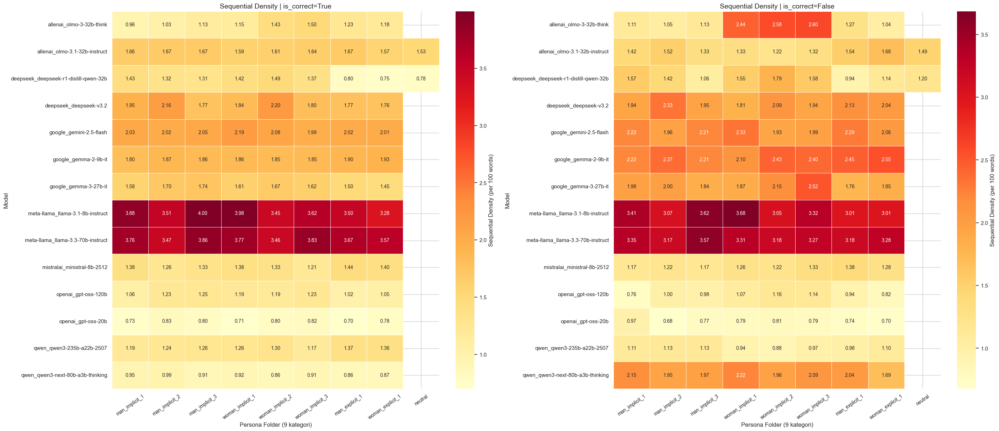

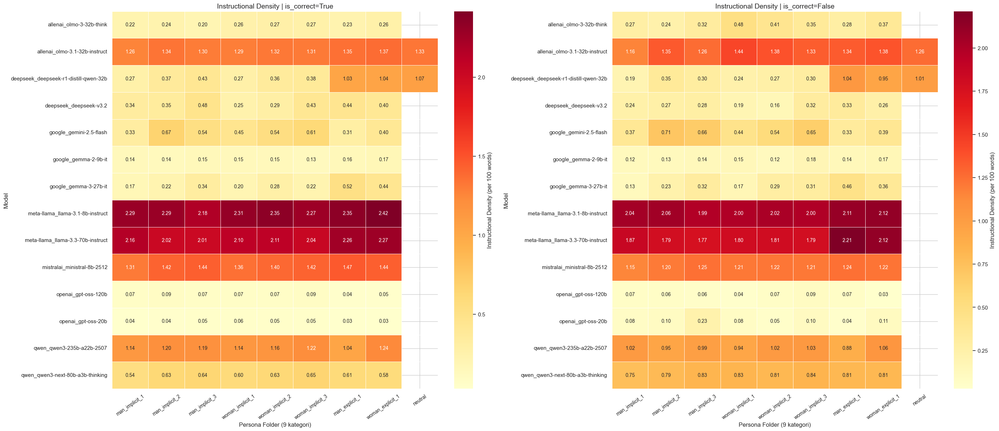

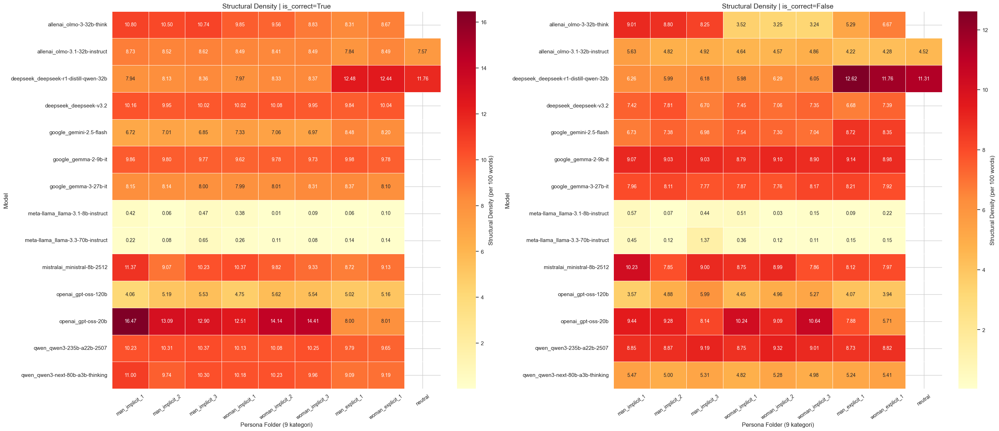

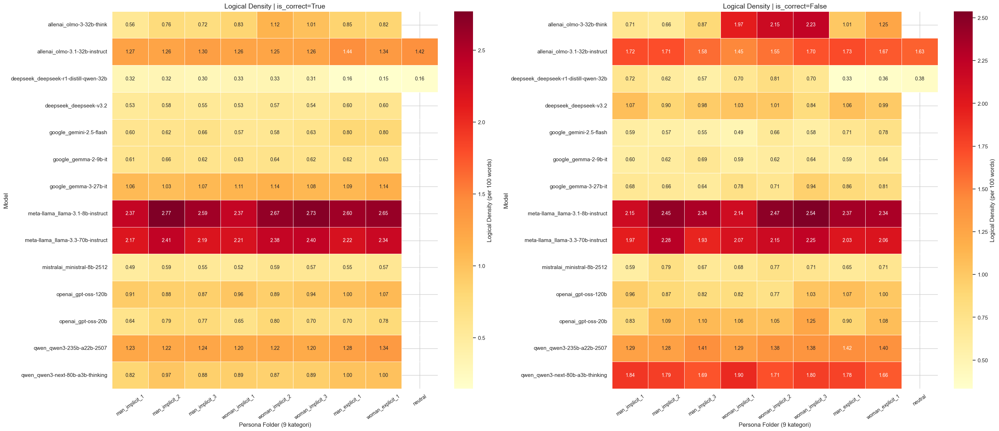

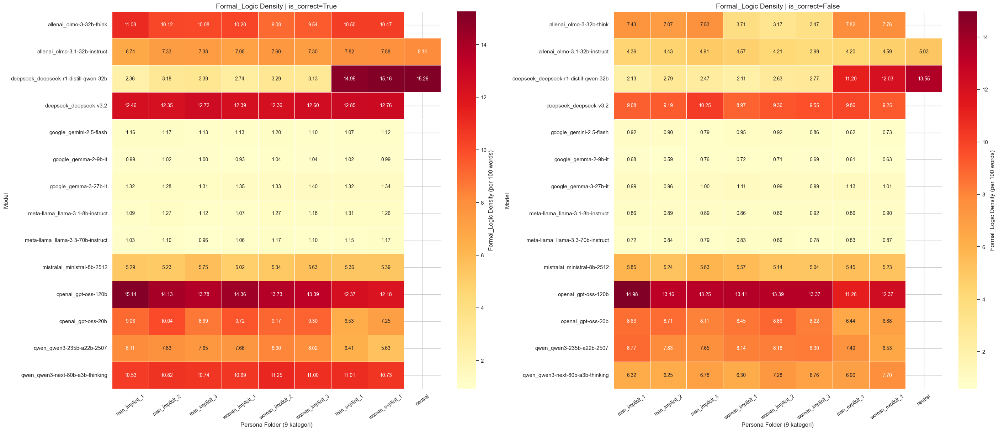

...

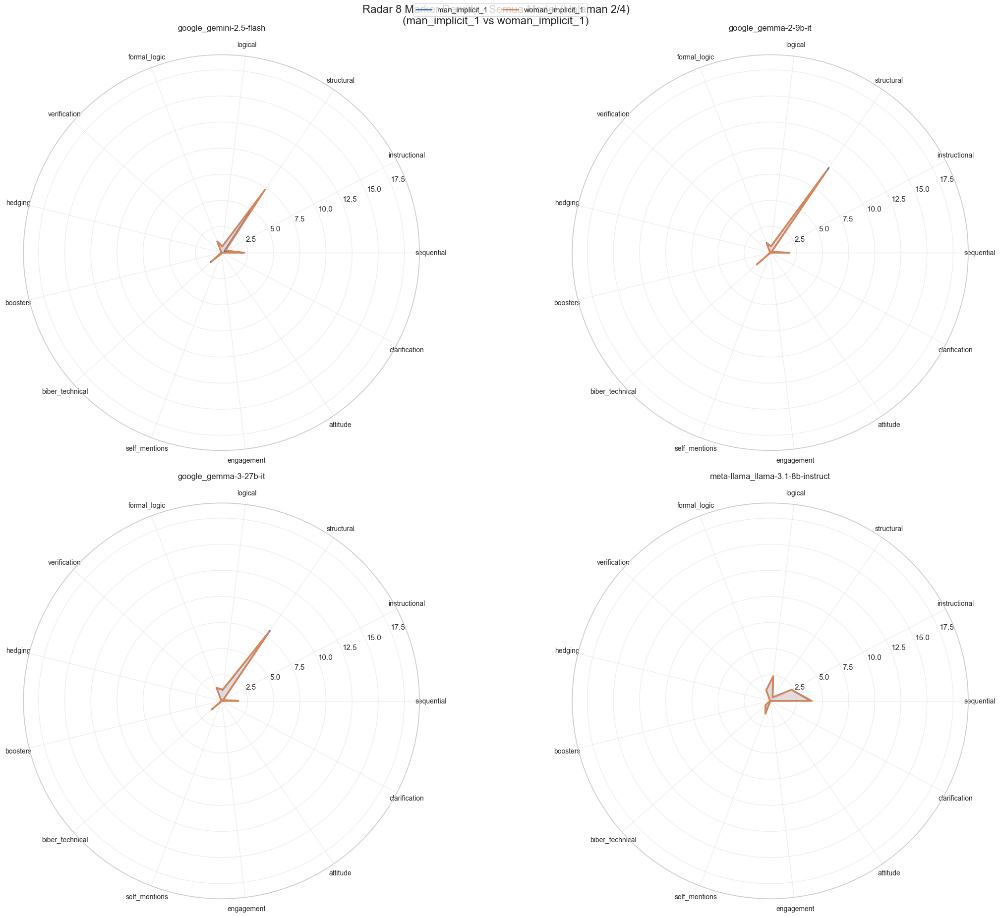

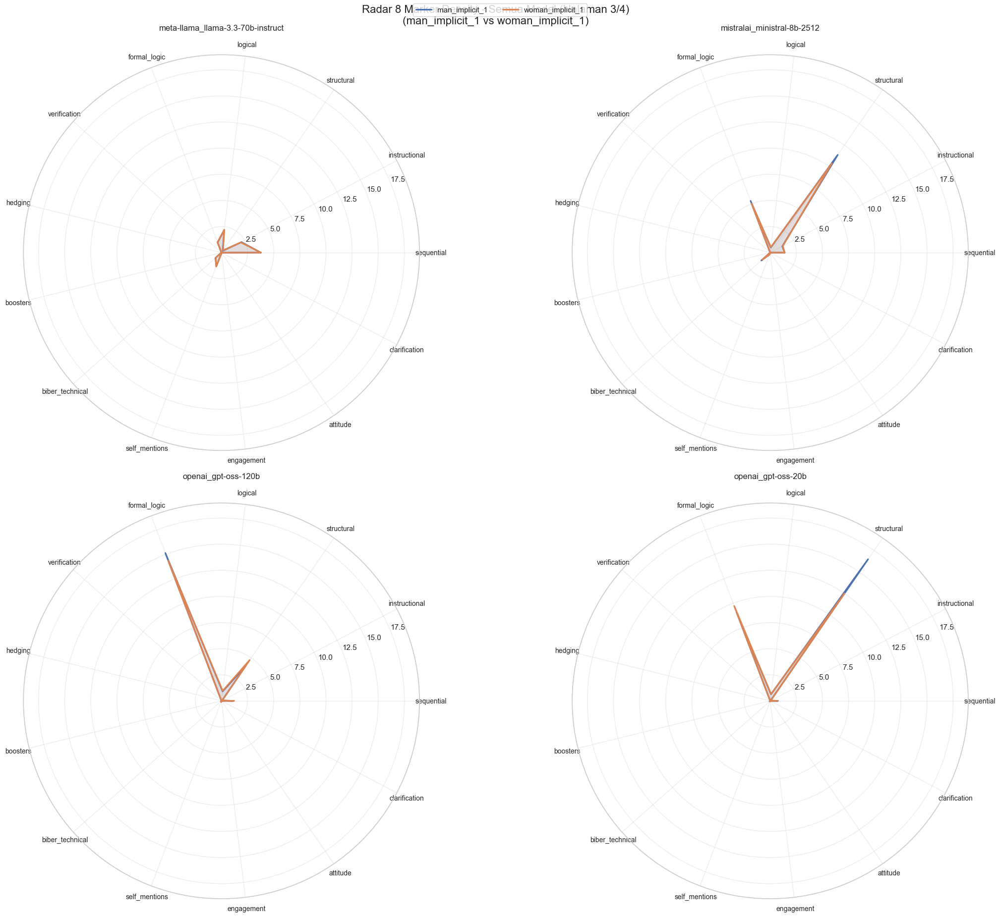

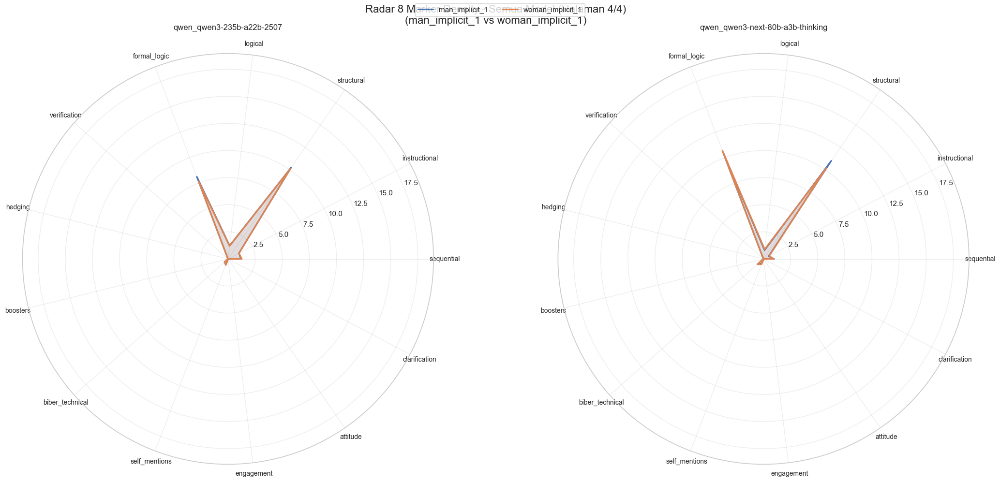

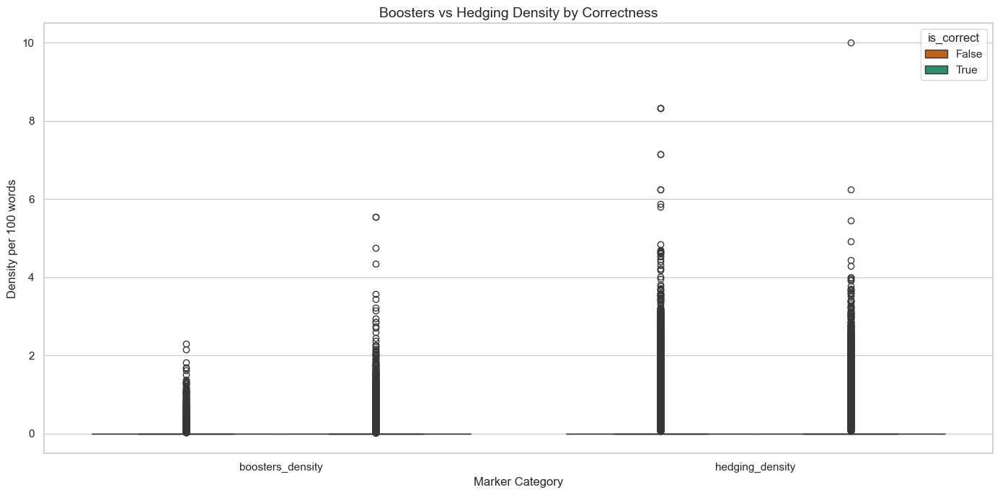

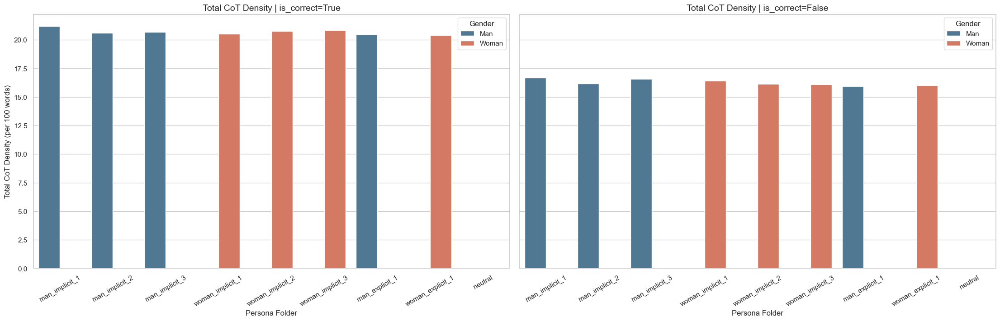

,model_name,persona_folder,is_correct,sequential_density_mean,sequential_density_std,instructional_density_mean,instructional_density_std,structural_density_mean,structural_density_std,logical_density_mean,logical_density_std,formal_logic_density_mean,formal_logic_density_std,verification_density_mean,verification_density_std,hedging_density_mean,hedging_density_std,boosters_density_mean,boosters_density_std,biber_technical_density_mean,biber_technical_density_std,self_mentions_density_mean,self_mentions_density_std,engagement_density_mean,engagement_density_std,attitude_density_mean,attitude_density_std,clarification_density_mean,clarification_density_std,total_cot_density_mean,total_cot_density_std,word_count_mean,word_count_std,n_samples
0,allenai_olmo-3-32b-think,man_implicit_1,False,1.112242,2.104588,0.271630,0.530742,9.013702,4.725783,0.708971,0.930132,7.433387,6.252030,0.020968,0.105815,0.090885,0.329367,0.002840,0.018186,0.759874,0.999702,0.111258,0.350377,0.160710,1.268546,0.012775,0.111367,0.003533,0.023682,21.350997,7.587841,250.328947,871.842469,76
1,allenai_olmo-3-32b-think,man_implicit_1,True,0.961393,1.846150,0.219534,0.511415,10.804177,4.984031,0.557164,0.943716,11.083603,7.929150,0.039451,0.186715,0.014543,0.118671,0.006800,0.086539,0.700895,0.882172,0.050077,0.251553,0.017203,0.253097,0.000618,0.018649,0.003339,0.044185,26.597775,7.641110,93.151247,249.685599,1243
2,allenai_olmo-3-32b-think,man_implicit_2,False,1.045915,1.899650,0.236735,0.520507,8.800225,4.958928,0.658456,0.809334,7.071325,5.690452,0.009051,0.049622,0.077008,0.297554,0.015902,0.117546,0.781752,1.045066,0.140143,0.404492,0.015118,0.111428,0.016847,0.129312,0.009965,0.058214,20.611580,6.602702,198.819672,719.024930,61
3,allenai_olmo-3-32b-think,man_implicit_2,True,1.031840,1.938026,0.238853,0.567827,10.495996,4.701710,0.756218,1.099688,10.115871,7.311428,0.029610,0.169403,0.011729,0.118384,0.005912,0.095803,0.653233,0.866538,0.051855,0.288798,0.033064,0.346772,0.000014,0.000498,0.002104,0.037608,25.202146,7.040600,81.413355,160.551152,1258
4,allenai_olmo-3-32b-think,man_implicit_3,False,1.133489,1.823772,0.315586,0.572763,8.253301,4.618980,0.867203,1.178634,7.529980,5.661367,0.023422,0.095857,0.071674,0.268668,0.015535,0.125401,0.670349,0.847924,0.203004,0.577183,0.008556,0.043454,0.014731,0.120373,0.006018,0.029307,20.445986,7.496647,287.159420,959.197392,69
5,allenai_olmo-3-32b-think,man_implicit_3,True,1.130658,2.085603,0.198258,0.555467,10.735981,5.136208,0.720605,1.155750,10.082622,8.889292,0.033298,0.194178,0.009731,0.110812,0.005572,0.096357,0.642021,0.896424,0.045645,0.285363,0.025211,0.274072,0.001094,0.037724,0.000971,0.024388,25.533710,8.317690,73.642400,92.573314,1250
6,allenai_olmo-3-32b-think,woman_implicit_1,False,2.440957,2.194771,0.483691,0.620012,3.516474,5.059970,1.972036,1.391055,3.713566,5.166381,0.252104,0.274027,0.982421,0.861114,0.028973,0.087581,0.458886,0.637563,0.930311,0.799542,0.170084,0.388125,0.011491,0.032386,0.094243,0.114923,15.145685,7.244620,1073.325397,1005.476236,126
7,allenai_olmo-3-32b-think,woman_implicit_1,True,1.149832,1.937062,0.257783,0.524406,9.850002,5.205835,0.829760,1.183172,10.195723,7.449178,0.075671,0.222714,0.109897,0.381295,0.010008,0.087493,0.686108,0.820596,0.220692,0.613766,0.038406,0.250889,0.003332,0.034568,0.013477,0.067698,25.298120,7.781210,167.756915,314.062226,1193
8,allenai_olmo-3-32b-think,woman_implicit_2,False,2.575339,2.067200,0.407026,0.454994,3.252829,5.399171,2.153066,1.300447,3.171779,5.248798,0.229885,0.229637,1.091799,1.005438,0.029036,0.103214,0.488060,0.760292,0.822198,0.731206,0.175144,0.355112,0.013857,0.032274,0.101485,0.146804,14.177279,7.294221,996.661157,694.399699,121
9,allenai_olmo-3-32b-think,woman_implicit_2,True,1.427272,2.216658,0.273163,0.556916,9.556837,5.713464,1.115882,1.383380,9.079642,8.081921,0.085370,0.235209,0.158887,0.470473,0.015378,0.106878,0.633685,0.839359,0.308623,0.721315,0.077996,0.467127,0.004722,0.061303,0.018276,0.096302,24.028999,8.283

In [9]:
# ===== 5) Visualisasi Thesis-Grade (Readable Layout) =====
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
})

# A. Heatmap: SEMUA kategori density untuk 9 persona vs model, dipisah is_correct
heat_input = (
    df.dropna(subset=["is_correct"])
    .groupby(["model_name", "persona_folder", "is_correct"], as_index=False)
    .agg(**{f"{cat}_density_mean": (f"{cat}_density", "mean") for cat in marker_categories + ["formal_logic"]})
)

def plot_density_heatmaps_all_categories(data, categories):
    for cat in categories:
        metric_col = f"{cat}_density_mean"
        fig, axes = plt.subplots(1, 2, figsize=(28, 12), constrained_layout=True)
        for ax, correctness in zip(axes, [True, False]):
            subset = data[data["is_correct"] == correctness]
            pivot = subset.pivot(index="model_name", columns="persona_folder", values=metric_col)
            pivot = pivot.reindex(columns=persona_order)
            sns.heatmap(
                pivot,
                ax=ax,
                cmap="YlOrRd",
                annot=True,
                fmt=".2f",
                annot_kws={"size": 10},
                linewidths=0.5,
                cbar_kws={"label": f"{cat.title()} Density (per 100 words)"},
            )
            ax.set_title(f"{cat.title()} Density | is_correct={correctness}")
            ax.set_xlabel("Persona Folder (9 kategori)")
            ax.set_ylabel("Model")
            ax.tick_params(axis="x", rotation=35, labelsize=10)
            ax.tick_params(axis="y", labelsize=11)
        plt.show()

plot_density_heatmaps_all_categories(heat_input, marker_categories + ["formal_logic"])

# A2. Heatmap khusus Formal Logic Density (lebih fokus)
formal_focus = heat_input
fig, axes = plt.subplots(1, 2, figsize=(28, 12), constrained_layout=True)
for ax, correctness in zip(axes, [True, False]):
    subset = formal_focus[formal_focus["is_correct"] == correctness]
    pivot = subset.pivot(index="model_name", columns="persona_folder", values="formal_logic_density_mean")
    pivot = pivot.reindex(columns=persona_order)
    sns.heatmap(
        pivot,
        ax=ax,
        cmap="Blues",
        annot=True,
        fmt=".2f",
        annot_kws={"size": 10},
        linewidths=0.5,
        cbar_kws={"label": "Formal Logic Density (per 100 words)"},
    )
    ax.set_title(f"Formal Logic Density | is_correct={correctness}")
    ax.set_xlabel("Persona Folder (9 kategori)")
    ax.set_ylabel("Model")
    ax.tick_params(axis="x", rotation=35, labelsize=10)
    ax.tick_params(axis="y", labelsize=11)
plt.show()

# B. Radar Chart: 8 marker untuk SEMUA model (dipecah per halaman agar terbaca)
radar_personas = ["man_implicit_1", "woman_implicit_1"]
radar_metrics = [f"{c}_density" for c in marker_categories]
model_list = sorted(df["model_name"].dropna().unique().tolist())

# Fokus default pada jawaban benar; fallback ke semua jika kosong.
radar_source = df[(df["persona_folder"].isin(radar_personas)) & (df["is_correct"] == True)].copy()
if radar_source.empty:
    radar_source = df[df["persona_folder"].isin(radar_personas)].copy()

radar_all = (
    radar_source.groupby(["model_name", "persona_folder"], as_index=False)[radar_metrics]
    .mean()
    .sort_values(["model_name", "persona_folder"])
)

angles = np.linspace(0, 2 * np.pi, len(radar_metrics), endpoint=False).tolist()
angles += angles[:1]

# Skala radial global agar perbandingan antar model konsisten
global_max = radar_all[radar_metrics].max().max() if not radar_all.empty else 1.0
radial_max = max(1.0, float(global_max) * 1.15)

models_per_page = 4
n_cols = 2
n_rows = 2

for start in range(0, len(model_list), models_per_page):
    page_models = model_list[start : start + models_per_page]
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(22, 18), subplot_kw={"polar": True}, constrained_layout=True
    )
    axes = np.array(axes).reshape(-1)

    for i, model in enumerate(page_models):
        ax = axes[i]
        model_df = radar_all[radar_all["model_name"] == model]
        for persona in radar_personas:
            row = model_df[model_df["persona_folder"] == persona]
            if row.empty:
                values = [0.0] * len(radar_metrics)
            else:
                values = row.iloc[0][radar_metrics].tolist()
            values += values[:1]
            ax.plot(angles, values, linewidth=2.3, label=persona)
            ax.fill(angles, values, alpha=0.14)

        ax.set_xticks(angles[:-1])
        ax.set_xticklabels([m.replace("_density", "") for m in radar_metrics], fontsize=10)
        ax.set_ylim(0, radial_max)
        ax.set_title(model, fontsize=12, pad=16)
        ax.grid(alpha=0.35)

    for j in range(len(page_models), len(axes)):
        fig.delaxes(axes[j])

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2, frameon=True, fontsize=11)
    page_no = (start // models_per_page) + 1
    total_pages = int(np.ceil(len(model_list) / models_per_page))
    fig.suptitle(
        f"Radar 8 Marker Density - Semua Model (Halaman {page_no}/{total_pages})\n(man_implicit_1 vs woman_implicit_1)",
        fontsize=16,
        y=1.02,
    )
    plt.show()

# C. Boxplot: Boosters vs Hedging dengan pembeda warna is_correct
box_df = df[["is_correct", "boosters_density", "hedging_density"]].copy()
box_long = box_df.melt(
    id_vars="is_correct",
    value_vars=["boosters_density", "hedging_density"],
    var_name="marker_type",
    value_name="density",
 )

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=box_long,
    x="marker_type",
    y="density",
    hue="is_correct",
    palette={True: "#1b9e77", False: "#d95f02"},
)
plt.title("Boosters vs Hedging Density by Correctness")
plt.xlabel("Marker Category")
plt.ylabel("Density per 100 words")
plt.legend(title="is_correct", fontsize=11)
plt.tight_layout()
plt.show()

# D. Barplot Total_CoT_Score (density) Man vs Woman per persona, dibedah is_correct
tot_df = df[df["gender"].isin(["Man", "Woman"])]
tot_agg = (
    tot_df
    .groupby(["persona_folder", "gender", "is_correct"], as_index=False)
    .agg(total_cot_density_mean=("total_cot_density", "mean"))
)
fig, axes = plt.subplots(1, 2, figsize=(22, 7), sharey=True, constrained_layout=True)
for ax, correctness in zip(axes, [True, False]):
    sub = tot_agg[tot_agg["is_correct"] == correctness]
    sns.barplot(
        data=sub,
        x="persona_folder",
        y="total_cot_density_mean",
        hue="gender",
        palette={"Man": "#457b9d", "Woman": "#e76f51"},
        ax=ax,
        errorbar=None,
    )
    ax.set_title(f"Total CoT Density | is_correct={correctness}")
    ax.set_xlabel("Persona Folder")
    ax.set_ylabel("Total CoT Density (per 100 words)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Gender")
plt.show()

comprehensive_report.head(10)

In [10]:
# ===== 6) Aggregated Persona Grouping & Radar Charts =====
# Modular functions untuk grouping dan visualization

def create_persona_groups_5(persona_folder):
    """
    Map 9 personas ke 5 groups:
    - man_explicit_avg
    - man_implicit_avg
    - neutral
    - woman_implicit_avg
    - woman_explicit_avg
    """
    text = str(persona_folder).lower() if pd.notna(persona_folder) else ""
    
    if "neutral" in text:
        return "neutral"
    elif "woman" in text or "women" in text:
        if "explicit" in text:
            return "woman_explicit_avg"
        else:
            return "woman_implicit_avg"
    elif "man" in text or "men" in text:
        if "explicit" in text:
            return "man_explicit_avg"
        else:
            return "man_implicit_avg"
    return None


def create_persona_groups_3(persona_folder):
    """
    Map 9 personas ke 3 groups:
    - man
    - neutral
    - woman
    """
    text = str(persona_folder).lower() if pd.notna(persona_folder) else ""
    
    if "neutral" in text:
        return "neutral"
    elif "woman" in text or "women" in text:
        return "woman"
    elif "man" in text or "men" in text:
        return "man"
    return None


# Tambahkan kolom persona_group untuk kedua setup
df["persona_group_5"] = df["persona_folder"].apply(create_persona_groups_5)
df["persona_group_3"] = df["persona_folder"].apply(create_persona_groups_3)

print("Persona Groups 5:", df["persona_group_5"].unique())
print("Persona Groups 3:", df["persona_group_3"].unique())


def aggregate_by_persona_groups(data, persona_group_col, metric_cols, filter_correct=True):
    """
    Aggregate data by model_name dan persona_group.
    Compute mean untuk semua metric columns.
    
    Parameters:
    - data: DataFrame
    - persona_group_col: column name untuk persona grouping
    - metric_cols: list of density columns to aggregate
    - filter_correct: default True (hanya is_correct=True), fallback ke semua jika kosong
    
    Returns:
    - Aggregated DataFrame
    """
    if filter_correct:
        filtered = data[data["is_correct"] == True].copy()
        if filtered.empty:
            filtered = data.copy()
    else:
        filtered = data.copy()
    
    agg_dict = {col: ("mean",) for col in metric_cols}
    aggregated = (
        filtered.groupby(["model_name", persona_group_col], as_index=False)[metric_cols]
        .mean()
        .sort_values(["model_name", persona_group_col])
    )
    
    return aggregated


# Definisikan list metric columns untuk radar
density_metrics = [f"{cat}_density" for cat in marker_categories]

# Aggregate untuk 5-group setup
df_agg_5 = aggregate_by_persona_groups(df, "persona_group_5", density_metrics, filter_correct=True)
print(f"\n5-Group Aggregated shape: {df_agg_5.shape}")
print(df_agg_5.head(10))

# Aggregate untuk 3-group setup
df_agg_3 = aggregate_by_persona_groups(df, "persona_group_3", density_metrics, filter_correct=True)
print(f"\n3-Group Aggregated shape: {df_agg_3.shape}")
print(df_agg_3.head(10))

Persona Groups 5: <StringArray>
[  'man_explicit_avg',   'man_implicit_avg', 'woman_explicit_avg',
 'woman_implicit_avg',            'neutral']
Length: 5, dtype: str
Persona Groups 3: <StringArray>
['man', 'woman', 'neutral']
Length: 3, dtype: str

5-Group Aggregated shape: (58, 15)
                              model_name     persona_group_5  \
0               allenai_olmo-3-32b-think    man_explicit_avg   
1               allenai_olmo-3-32b-think    man_implicit_avg   
2               allenai_olmo-3-32b-think  woman_explicit_avg   
3               allenai_olmo-3-32b-think  woman_implicit_avg   
4          allenai_olmo-3.1-32b-instruct    man_explicit_avg   
5          allenai_olmo-3.1-32b-instruct    man_implicit_avg   
6          allenai_olmo-3.1-32b-instruct             neutral   
7          allenai_olmo-3.1-32b-instruct  woman_explicit_avg   
8          allenai_olmo-3.1-32b-instruct  woman_implicit_avg   
9  deepseek_deepseek-r1-distill-qwen-32b    man_explicit_avg   

   sequenti

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\3200043971.py:70: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


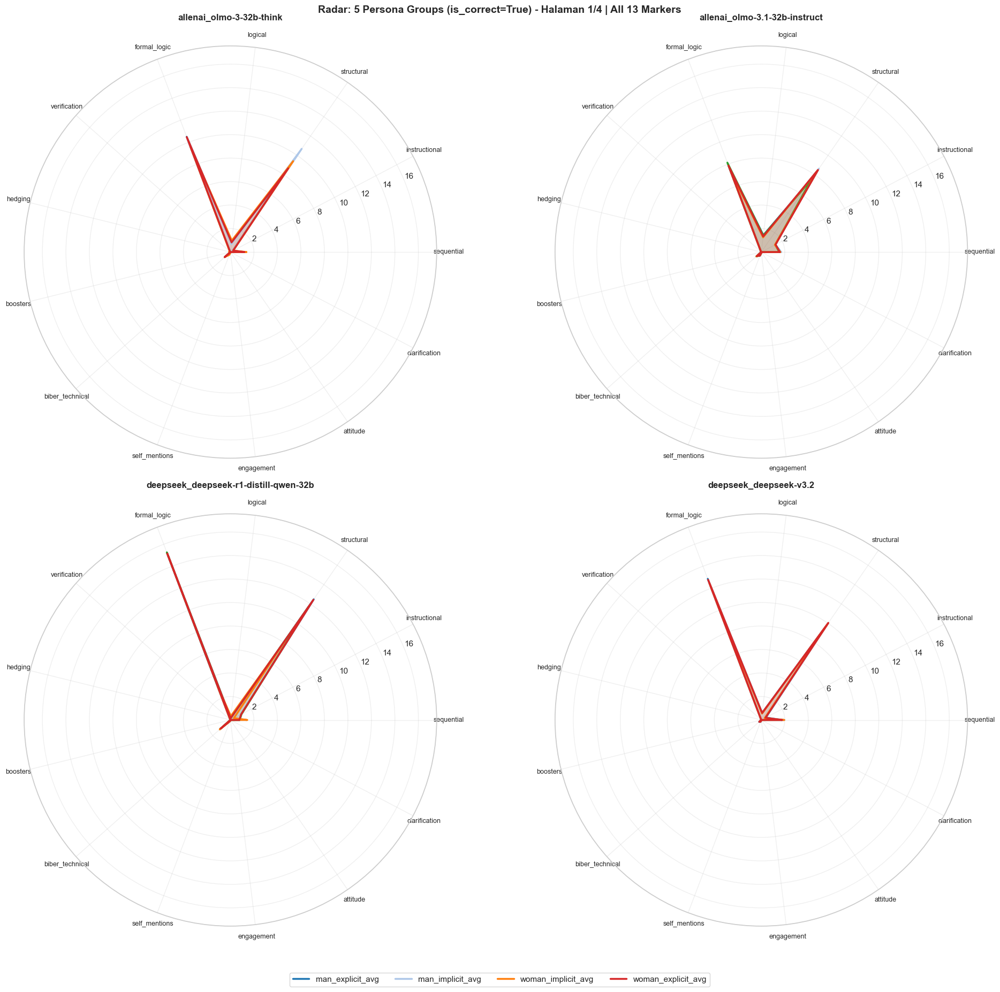

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\3200043971.py:70: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


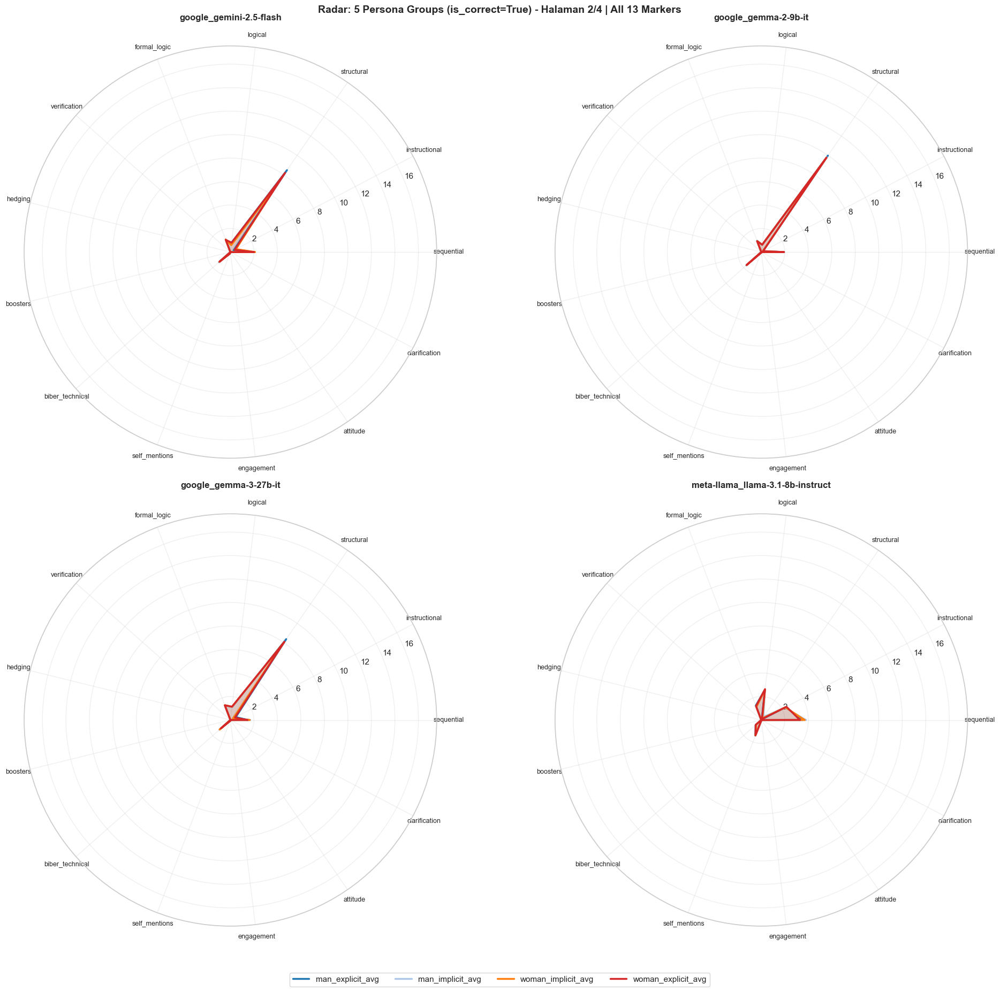

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\3200043971.py:70: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


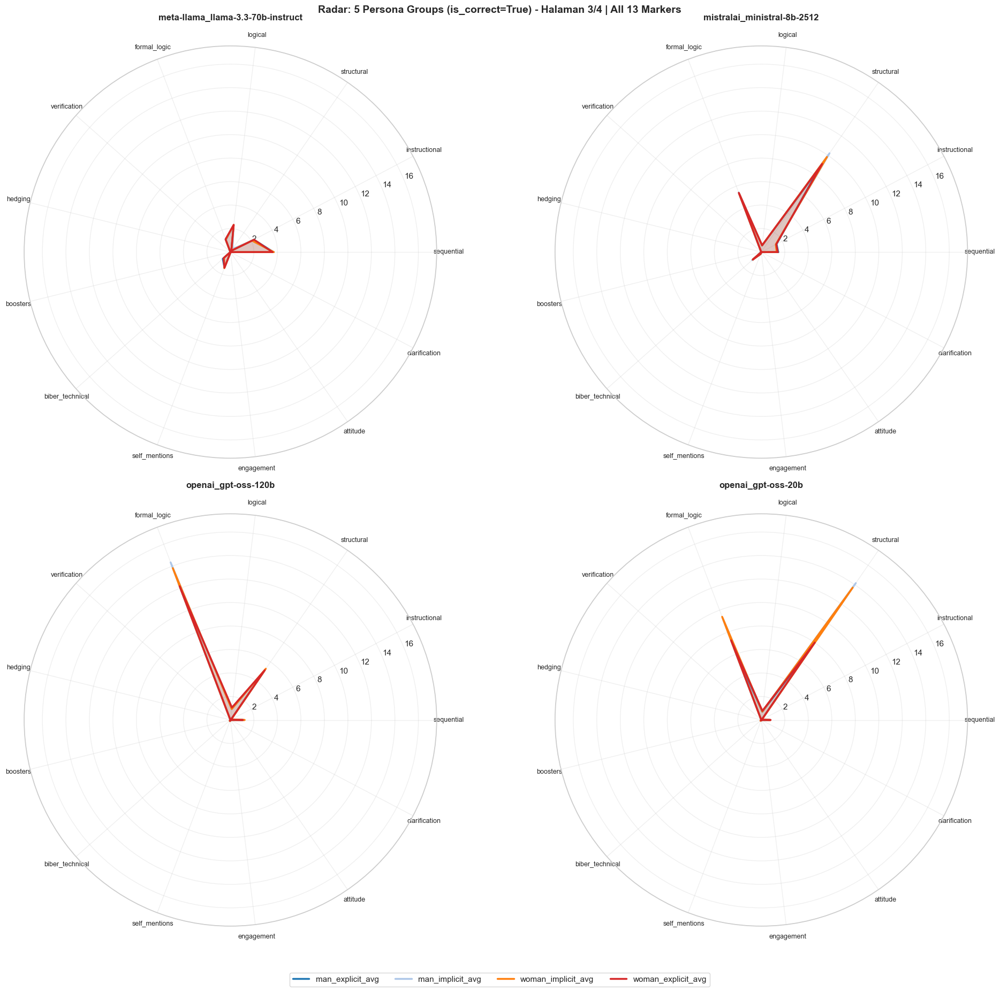

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\3200043971.py:70: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


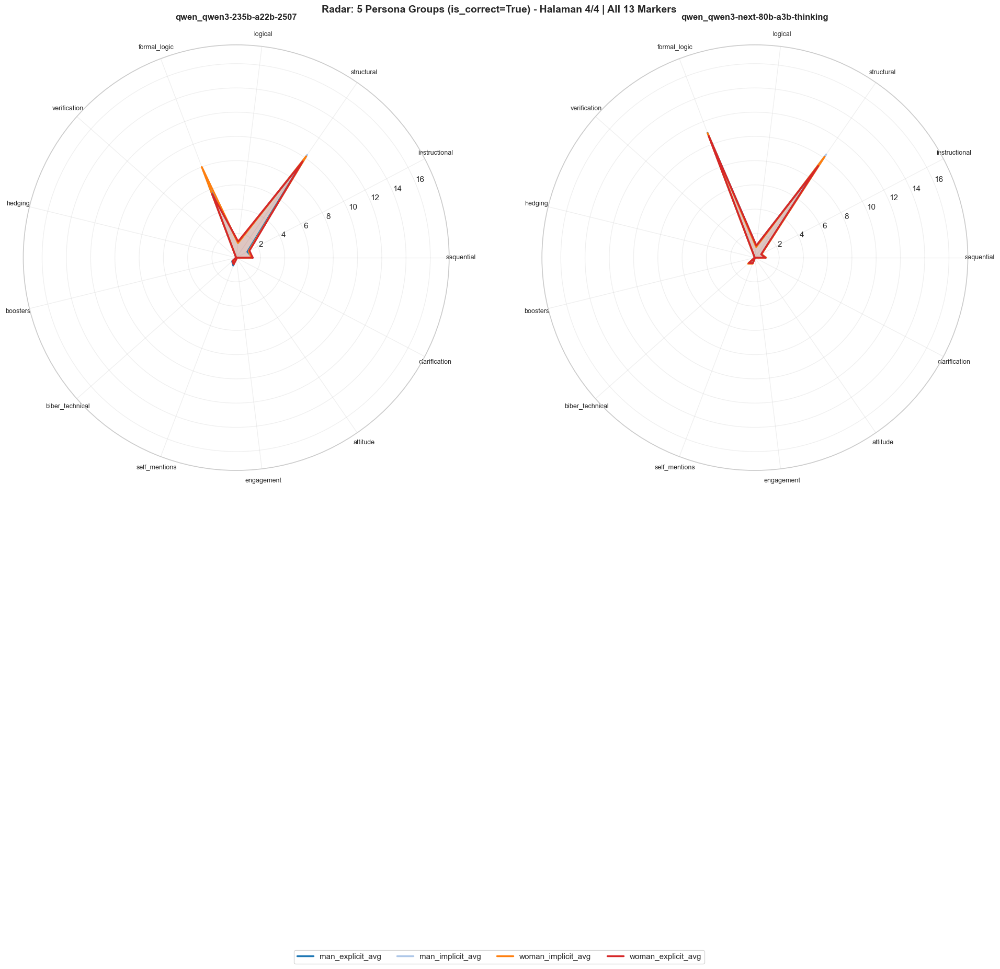

In [11]:
# ===== 7) Radar Chart Visualization (5-Group Setup) =====
# Visualisasi radar untuk 5 persona groups: man_explicit, man_implicit, neutral, woman_implicit, woman_explicit

def plot_radar_5_groups(agg_data, density_metrics, title_suffix=""):
    """
    Plot radar charts untuk 5-group aggregation.
    Satu subplot per model, masing-masing menunjukkan 5 persona groups.
    """
    model_list = sorted(agg_data["model_name"].unique().tolist())
    group_order_5 = ["man_explicit_avg", "man_implicit_avg", "neutral", "woman_implicit_avg", "woman_explicit_avg"]
    
    angles = np.linspace(0, 2 * np.pi, len(density_metrics), endpoint=False).tolist()
    angles += angles[:1]
    
    # Hitung global max untuk consistent scaling
    global_max = agg_data[density_metrics].max().max() if not agg_data.empty else 1.0
    radial_max = max(1.0, float(global_max) * 1.15)
    
    # Color palette untuk 5 groups
    colors = {
        "man_explicit_avg": "#1f77b4",
        "man_implicit_avg": "#aec7e8",
        "neutral": "#2ca02c",
        "woman_implicit_avg": "#ff7f0e",
        "woman_explicit_avg": "#d62728",
    }
    
    models_per_page = 4
    n_cols = 2
    n_rows = 2
    
    for start in range(0, len(model_list), models_per_page):
        page_models = model_list[start : start + models_per_page]
        fig, axes = plt.subplots(
            n_rows, n_cols, figsize=(20, 18), subplot_kw={"polar": True}, constrained_layout=True
        )
        axes = np.array(axes).reshape(-1)
        
        for i, model in enumerate(page_models):
            ax = axes[i]
            model_data = agg_data[agg_data["model_name"] == model]
            
            for group in group_order_5:
                group_data = model_data[model_data["persona_group_5"] == group]
                if not group_data.empty:
                    values = group_data[density_metrics].iloc[0].tolist()
                    values += values[:1]
                    ax.plot(angles, values, linewidth=2.5, label=group, color=colors.get(group, "#gray"))
                    ax.fill(angles, values, alpha=0.12, color=colors.get(group, "#gray"))
            
            ax.set_xticks(angles[:-1])
            ax.set_xticklabels([m.replace("_density", "") for m in density_metrics], fontsize=9)
            ax.set_ylim(0, radial_max)
            ax.set_title(f"{model}", fontsize=12, fontweight="bold", pad=16)
            ax.grid(alpha=0.3)
        
        for j in range(len(page_models), len(axes)):
            fig.delaxes(axes[j])
        
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=5, frameon=True, fontsize=11, bbox_to_anchor=(0.5, -0.02))
        page_no = (start // models_per_page) + 1
        total_pages = int(np.ceil(len(model_list) / models_per_page))
        fig.suptitle(
            f"Radar: 5 Persona Groups (is_correct=True) - Halaman {page_no}/{total_pages}{title_suffix}",
            fontsize=14,
            fontweight="bold",
            y=0.98,
        )
        plt.tight_layout()
        plt.show()

plot_radar_5_groups(df_agg_5, density_metrics, " | All 13 Markers")


C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2812514176.py:68: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


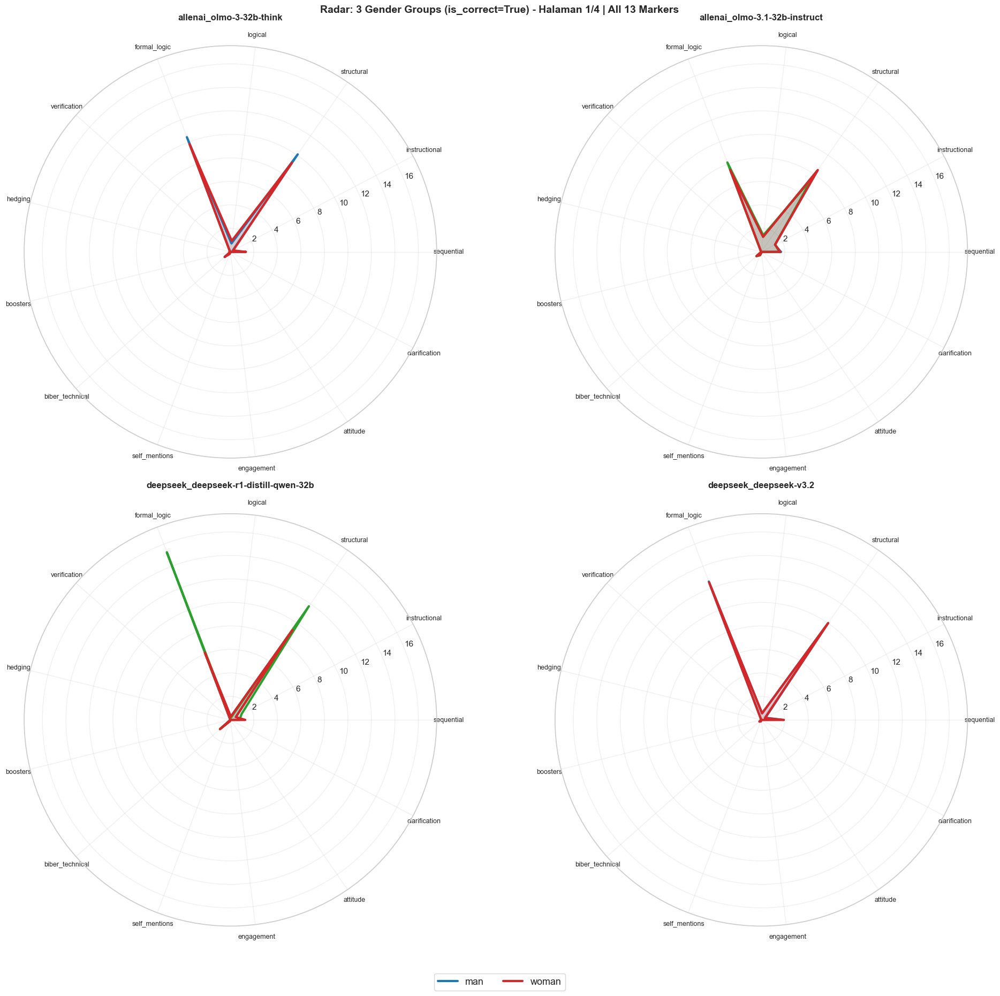

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2812514176.py:68: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


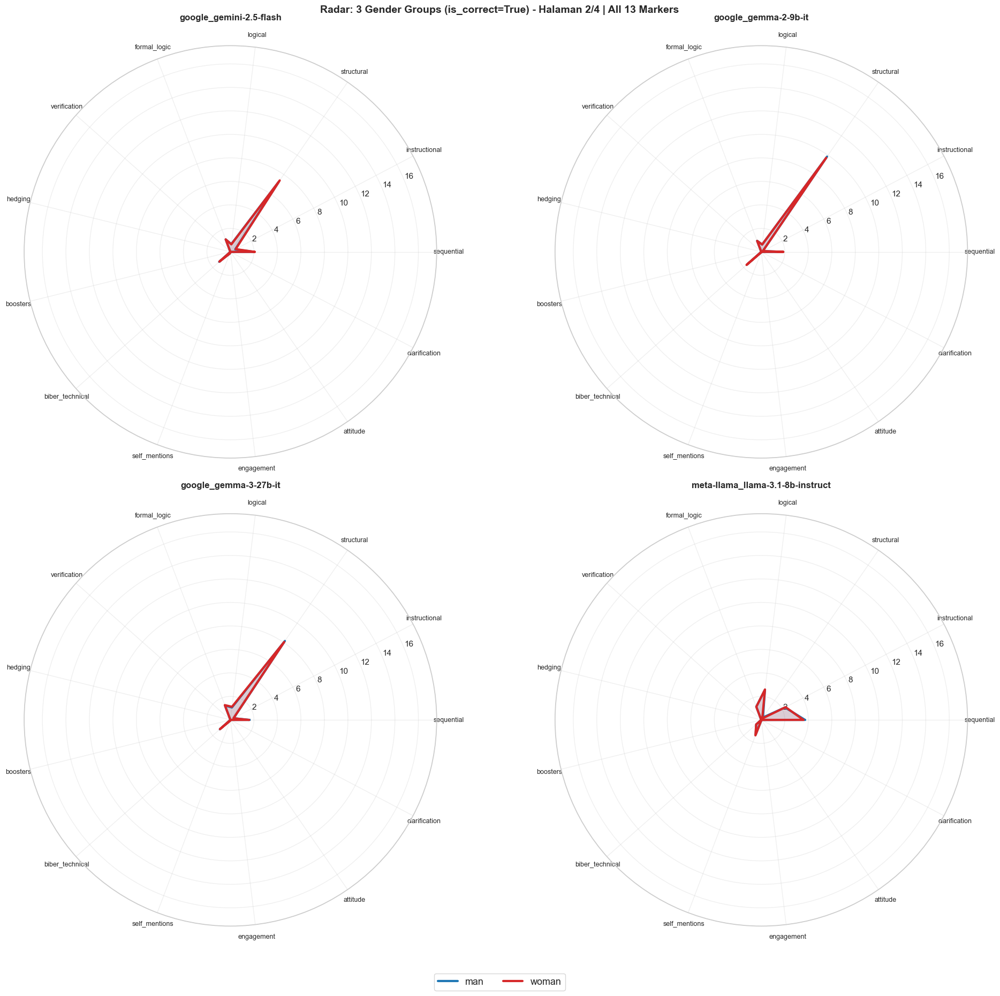

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2812514176.py:68: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


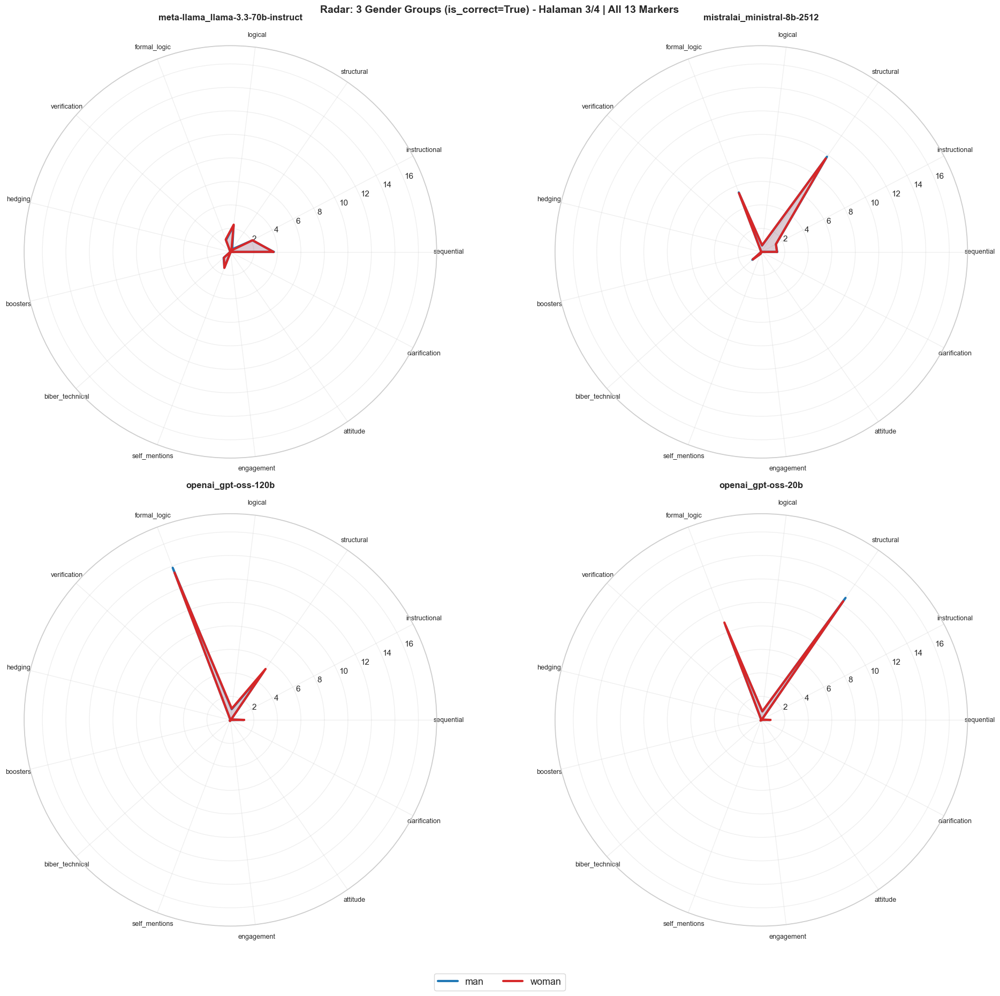

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2812514176.py:68: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


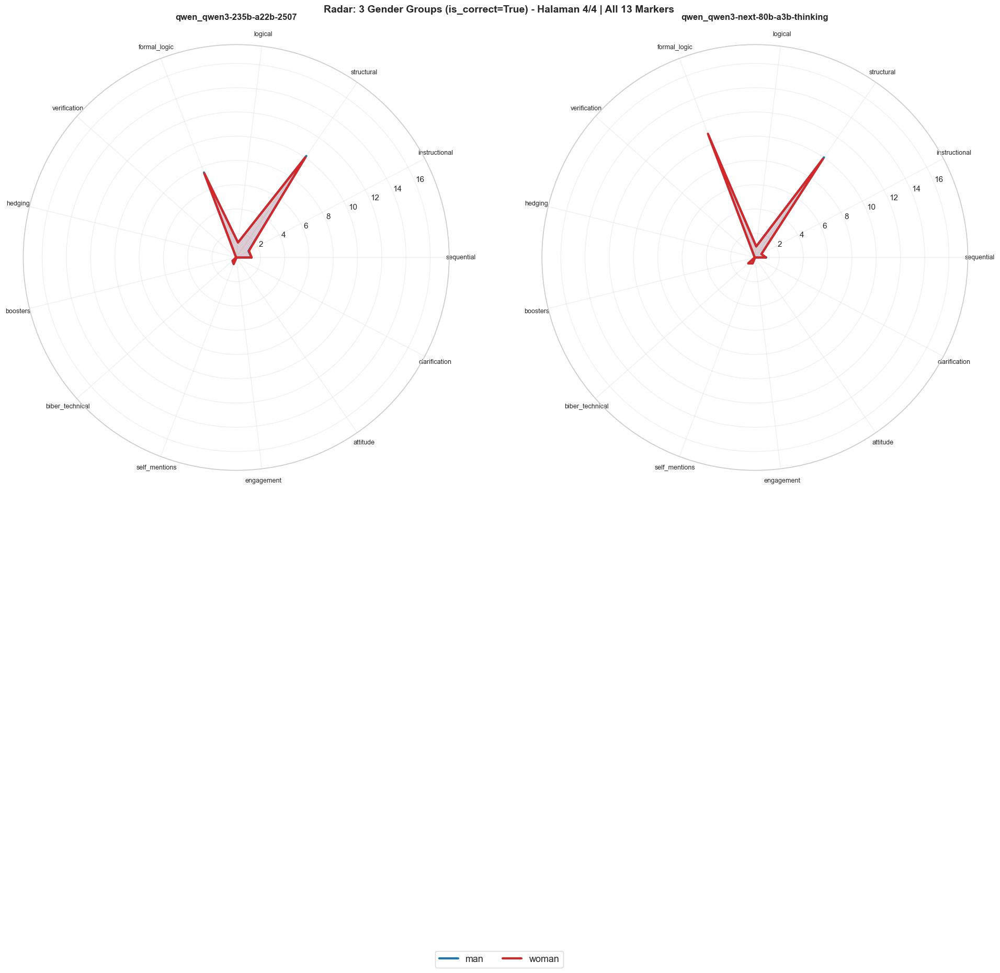

In [12]:
# ===== 8) Radar Chart Visualization (3-Group Setup) =====
# Visualisasi radar untuk 3 persona groups: man, neutral, woman

def plot_radar_3_groups(agg_data, density_metrics, title_suffix=""):
    """
    Plot radar charts untuk 3-group aggregation.
    Satu subplot per model, masing-masing menunjukkan 3 persona groups (gender-based).
    """
    model_list = sorted(agg_data["model_name"].unique().tolist())
    group_order_3 = ["man", "neutral", "woman"]
    
    angles = np.linspace(0, 2 * np.pi, len(density_metrics), endpoint=False).tolist()
    angles += angles[:1]
    
    # Hitung global max untuk consistent scaling
    global_max = agg_data[density_metrics].max().max() if not agg_data.empty else 1.0
    radial_max = max(1.0, float(global_max) * 1.15)
    
    # Color palette untuk 3 groups
    colors_3 = {
        "man": "#1f77b4",
        "neutral": "#2ca02c",
        "woman": "#d62728",
    }
    
    models_per_page = 4
    n_cols = 2
    n_rows = 2
    
    for start in range(0, len(model_list), models_per_page):
        page_models = model_list[start : start + models_per_page]
        fig, axes = plt.subplots(
            n_rows, n_cols, figsize=(20, 18), subplot_kw={"polar": True}, constrained_layout=True
        )
        axes = np.array(axes).reshape(-1)
        
        for i, model in enumerate(page_models):
            ax = axes[i]
            model_data = agg_data[agg_data["model_name"] == model]
            
            for group in group_order_3:
                group_data = model_data[model_data["persona_group_3"] == group]
                if not group_data.empty:
                    values = group_data[density_metrics].iloc[0].tolist()
                    values += values[:1]
                    ax.plot(angles, values, linewidth=3.0, label=group, color=colors_3.get(group, "#gray"))
                    ax.fill(angles, values, alpha=0.15, color=colors_3.get(group, "#gray"))
            
            ax.set_xticks(angles[:-1])
            ax.set_xticklabels([m.replace("_density", "") for m in density_metrics], fontsize=9)
            ax.set_ylim(0, radial_max)
            ax.set_title(f"{model}", fontsize=12, fontweight="bold", pad=16)
            ax.grid(alpha=0.3)
        
        for j in range(len(page_models), len(axes)):
            fig.delaxes(axes[j])
        
        handles, labels = axes[0].get_legend_handles_labels()
        fig.legend(handles, labels, loc="upper center", ncol=3, frameon=True, fontsize=13, bbox_to_anchor=(0.5, -0.02))
        page_no = (start // models_per_page) + 1
        total_pages = int(np.ceil(len(model_list) / models_per_page))
        fig.suptitle(
            f"Radar: 3 Gender Groups (is_correct=True) - Halaman {page_no}/{total_pages}{title_suffix}",
            fontsize=14,
            fontweight="bold",
            y=0.98,
        )
        plt.tight_layout()
        plt.show()

plot_radar_3_groups(df_agg_3, density_metrics, " | All 13 Markers")


In [13]:
# ===== 9) Summary Statistics & Thesis-Ready Export =====

# Summary table: Mean marker densities per model & persona group (5-group)
summary_5 = df_agg_5.copy()
summary_5_display = summary_5.sort_values(["model_name", "persona_group_5"]).round(3)
print("=" * 120)
print("SUMMARY TABLE: 5-GROUP PERSONA AGGREGATION (is_correct=True)")
print("=" * 120)
print(summary_5_display.to_string(index=False))

# Summary table: 3-group
summary_3 = df_agg_3.copy()
summary_3_display = summary_3.sort_values(["model_name", "persona_group_3"]).round(3)
print("\n" + "=" * 120)
print("SUMMARY TABLE: 3-GROUP GENDER AGGREGATION (is_correct=True)")
print("=" * 120)
print(summary_3_display.to_string(index=False))

# Export aggregated results to CSV untuk thesis
csv_5_path = Path("aggregated_5_groups_markers.csv")
csv_3_path = Path("aggregated_3_groups_markers.csv")

summary_5_display.to_csv(csv_5_path, index=False)
summary_3_display.to_csv(csv_3_path, index=False)

print(f"\n✅ Exported 5-group summary to: {csv_5_path.resolve()}")
print(f"✅ Exported 3-group summary to: {csv_3_path.resolve()}")

# Key insights
print("\n" + "=" * 120)
print("KEY INSIGHTS (is_correct=True)")
print("=" * 120)

# Top 3 markers dengan highest average density
top_markers = df[density_metrics].mean().nlargest(3)
print("\n📊 Top 3 Highest Average Marker Densities:")
for i, (marker, val) in enumerate(top_markers.items(), 1):
    print(f"   {i}. {marker.replace('_density', '')}: {val:.3f} per 100 words")

# Differences mellan groups
print("\n🔍 Mean Marker Density Comparison (5-groups):")
for cat in ["sequential", "instructional", "formal_logic", "total_cot"]:
    metric = f"{cat}_density"
    if metric in summary_5.columns:
        mean_by_group = summary_5.groupby("persona_group_5")[metric].mean()
        print(f"\n   {cat.upper()}:")
        print(mean_by_group.round(3).to_string())

# Gender-based comparison
print("\n🔍 Mean Marker Density Comparison (3-groups/Gender):")
for cat in ["sequential", "instructional", "formal_logic", "total_cot"]:
    metric = f"{cat}_density"
    if metric in summary_3.columns:
        mean_by_group = summary_3.groupby("persona_group_3")[metric].mean()
        print(f"\n   {cat.upper()}:")
        print(mean_by_group.round(3).to_string())

print("\n" + "=" * 120)
print("ANALYSIS COMPLETE ✓")
print("=" * 120)
print(f"Total samples analyzed: {len(df):,}")
print(f"Models included: {df['model_name'].nunique()}")
print(f"Marker categories: {len(marker_categories)}")
print(f"Analysis date: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")
print("=" * 120)


SUMMARY TABLE: 5-GROUP PERSONA AGGREGATION (is_correct=True)
                           model_name    persona_group_5  sequential_density  instructional_density  structural_density  logical_density  formal_logic_density  verification_density  hedging_density  boosters_density  biber_technical_density  self_mentions_density  engagement_density  attitude_density  clarification_density
             allenai_olmo-3-32b-think   man_explicit_avg               1.235                  0.229               8.311            0.846                10.496                 0.035            0.012             0.010                    0.642                  0.044               0.030             0.003                  0.006
             allenai_olmo-3-32b-think   man_implicit_avg               1.041                  0.219              10.678            0.678                10.425                 0.034            0.012             0.006                    0.665                  0.049               0.025      

# Token Usage Analysis: Verbosity Across Personas
Analisis bagaimana persona dan model mempengaruhi output verbosity menggunakan token metrics (completion_tokens & total_tokens)

In [14]:
# ===== 10) Token Data Aggregation by Persona Groups =====
# Aggregate completion_tokens dan total_tokens berdasarkan model dan persona groups

# Cek ketersediaan kolom token
token_cols_check = [col for col in df.columns if 'token' in col.lower()]
print(f"Available token columns: {token_cols_check}")

# Jika kolom token ada, siapkan untuk aggregation
if "completion_tokens" in df.columns and "total_tokens" in df.columns:
    # Data untuk token analysis (filter is_correct=True untuk konsistensi dengan linguistic analysis)
    df_tokens = df[df["is_correct"] == True].copy() if (df["is_correct"] == True).any() else df.copy()
    
    # Aggregation untuk 5-group setup
    token_metrics = ["completion_tokens", "total_tokens"]
    df_token_agg_5 = (
        df_tokens.groupby(["model_name", "persona_group_5"], as_index=False)[token_metrics]
        .mean()
        .sort_values(["model_name", "persona_group_5"])
        .round(2)
    )
    
    print(f"\n5-Group Token Aggregation shape: {df_token_agg_5.shape}")
    print(df_token_agg_5.head(10))
    
    # Aggregation untuk 3-group setup
    df_token_agg_3 = (
        df_tokens.groupby(["model_name", "persona_group_3"], as_index=False)[token_metrics]
        .mean()
        .sort_values(["model_name", "persona_group_3"])
        .round(2)
    )
    
    print(f"\n3-Group Token Aggregation shape: {df_token_agg_3.shape}")
    print(df_token_agg_3.head(10))
    
    # Export to CSV
    csv_token_5_path = Path("token_usage_5_groups.csv")
    csv_token_3_path = Path("token_usage_3_groups.csv")
    
    df_token_agg_5.to_csv(csv_token_5_path, index=False)
    df_token_agg_3.to_csv(csv_token_3_path, index=False)
    
    print(f"\n✅ Exported token 5-group summary to: {csv_token_5_path.resolve()}")
    print(f"✅ Exported token 3-group summary to: {csv_token_3_path.resolve()}")
else:
    print("⚠️  Token columns not found. Please verify dataset column names.")

Available token columns: []
⚠️  Token columns not found. Please verify dataset column names.


In [15]:
# ===== 11) Token Usage Visualization (Bar Charts) =====
# Visualisasi verbosity menggunakan completion_tokens dan total_tokens

if "completion_tokens" in df.columns and "total_tokens" in df.columns:
    # Define persona group orders untuk consistent visualization
    group_order_5 = ["man_explicit_avg", "man_implicit_avg", "neutral", "woman_implicit_avg", "woman_explicit_avg"]
    group_order_3 = ["man", "neutral", "woman"]
    
    # ========== A) COMPLETION TOKENS (5-group) ==========
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    
    # Sort data untuk visual clarity
    df_token_agg_5_sorted = df_token_agg_5.copy()
    df_token_agg_5_sorted["persona_group_5"] = pd.Categorical(
        df_token_agg_5_sorted["persona_group_5"],
        categories=group_order_5,
        ordered=True
    )
    df_token_agg_5_sorted = df_token_agg_5_sorted.sort_values(["persona_group_5", "model_name"])
    
    sns.barplot(
        data=df_token_agg_5_sorted,
        x="persona_group_5",
        y="completion_tokens",
        hue="model_name",
        palette="Set2",
        ax=ax,
    )
    
    ax.set_title("Average Completion Tokens by Persona Groups (5-Group Setup)\nHigher = More Verbose", 
                 fontsize=14, fontweight="bold", pad=16)
    ax.set_xlabel("Persona Group", fontsize=12, fontweight="bold")
    ax.set_ylabel("Average Completion Tokens", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", rotation=25, labelsize=11)
    ax.tick_params(axis="y", labelsize=11)
    ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, title_fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # ========== B) TOTAL TOKENS (5-group) ==========
    fig, ax = plt.subplots(figsize=(16, 7), constrained_layout=True)
    
    sns.barplot(
        data=df_token_agg_5_sorted,
        x="persona_group_5",
        y="total_tokens",
        hue="model_name",
        palette="Set2",
        ax=ax,
    )
    
    ax.set_title("Average Total Tokens by Persona Groups (5-Group Setup)\nHigher = More Response Length", 
                 fontsize=14, fontweight="bold", pad=16)
    ax.set_xlabel("Persona Group", fontsize=12, fontweight="bold")
    ax.set_ylabel("Average Total Tokens", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", rotation=25, labelsize=11)
    ax.tick_params(axis="y", labelsize=11)
    ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, title_fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # ========== C) COMPLETION TOKENS (3-group Gender) ==========
    fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
    
    df_token_agg_3_sorted = df_token_agg_3.copy()
    df_token_agg_3_sorted["persona_group_3"] = pd.Categorical(
        df_token_agg_3_sorted["persona_group_3"],
        categories=group_order_3,
        ordered=True
    )
    df_token_agg_3_sorted = df_token_agg_3_sorted.sort_values(["persona_group_3", "model_name"])
    
    sns.barplot(
        data=df_token_agg_3_sorted,
        x="persona_group_3",
        y="completion_tokens",
        hue="model_name",
        palette="Set1",
        ax=ax,
    )
    
    ax.set_title("Average Completion Tokens by Gender Groups (3-Group Setup)\nHigher = More Verbose", 
                 fontsize=14, fontweight="bold", pad=16)
    ax.set_xlabel("Gender Group", fontsize=12, fontweight="bold")
    ax.set_ylabel("Average Completion Tokens", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=11)
    ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, title_fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # ========== D) TOTAL TOKENS (3-group Gender) ==========
    fig, ax = plt.subplots(figsize=(12, 7), constrained_layout=True)
    
    sns.barplot(
        data=df_token_agg_3_sorted,
        x="persona_group_3",
        y="total_tokens",
        hue="model_name",
        palette="Set1",
        ax=ax,
    )
    
    ax.set_title("Average Total Tokens by Gender Groups (3-Group Setup)\nHigher = More Response Length", 
                 fontsize=14, fontweight="bold", pad=16)
    ax.set_xlabel("Gender Group", fontsize=12, fontweight="bold")
    ax.set_ylabel("Average Total Tokens", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", labelsize=12)
    ax.tick_params(axis="y", labelsize=11)
    ax.legend(title="Model", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, title_fontsize=10)
    ax.grid(axis="y", alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Print summary insights
    print("\n" + "=" * 100)
    print("TOKEN USAGE INSIGHTS (is_correct=True)")
    print("=" * 100)
    
    print("\n📊 Average Completion Tokens by Persona Group (5-group):")
    completion_by_group_5 = df_token_agg_5.groupby("persona_group_5")["completion_tokens"].mean().sort_values(ascending=False)
    print(completion_by_group_5.round(2).to_string())
    
    print("\n📊 Average Completion Tokens by Gender (3-group):")
    completion_by_group_3 = df_token_agg_3.groupby("persona_group_3")["completion_tokens"].mean().sort_values(ascending=False)
    print(completion_by_group_3.round(2).to_string())
    
    print("\n📊 Model Verbosity Ranking (by avg completion_tokens):")
    model_verbosity = df_token_agg_5.groupby("model_name")["completion_tokens"].mean().sort_values(ascending=False)
    for i, (model, tokens) in enumerate(model_verbosity.items(), 1):
        print(f"   {i}. {model}: {tokens:.2f} tokens")
    
    print("\n" + "=" * 100)
else:
    print("⚠️  Token columns not found. Skipping visualization.")

⚠️  Token columns not found. Skipping visualization.


# Model Rankings by Linguistic Marker Category
Urutan model dari nilai tertinggi hingga terendah untuk setiap jenis linguistic marker

In [16]:
# ===== 12) Model Rankings by Linguistic Marker (Highest to Lowest) =====
# Rank models untuk setiap marker category berdasarkan nilai densitas di 5-group aggregation

# ===== ENSURE ALL REQUIRED VARIABLES ARE DEFINED =====
# (For robustness if this cell is run independently)
if 'marker_categories' not in locals():
    marker_categories = [
        "sequential", "instructional", "structural", "logical",
        "formal_logic", "verification", "hedging", "boosters",
        "biber_technical", "self_mentions", "engagement", "attitude", "clarification",
    ]

if 'df_agg_5' not in locals() or 'df_agg_3' not in locals():
    print("⚠️ WARNING: Required dataframe (df_agg_5, df_agg_3) not found in memory.")
    print("Please run earlier cells first to generate aggregated data.")
    raise NameError("Missing required dataframes")

print("=" * 140)
print("🏆 MODEL RANKINGS BY LINGUISTIC MARKER CATEGORY (5-GROUP SETUP)")
print("=" * 140)
print("Urutan: Tertinggi → Terendah (berdasarkan rata-rata nilai density per persona group)\n")

# Prepare ranking data: aggregasi setiap model untuk setiap marker
for marker_cat in marker_categories:
    marker_col = f"{marker_cat}_density"
    
    # Hitung mean per model (across all 5 persona groups)
    model_marker_mean = df_agg_5.groupby("model_name")[marker_col].mean().sort_values(ascending=False)
    
    print(f"\n📊 {marker_cat.upper()}")
    print("-" * 140)
    
    ranking_data = []
    for rank, (model, value) in enumerate(model_marker_mean.items(), 1):
        ranking_data.append({
            "Rank": rank,
            "Model": model,
            "Avg Density": f"{value:.4f}",
            "Per 100 Words": f"{value:.2f}"
        })
    
    ranking_df = pd.DataFrame(ranking_data)
    print(ranking_df.to_string(index=False))
    print()

print("\n" + "=" * 140)
print("📈 TOP MARKER BY MODEL (Highest average density across all markers)")
print("=" * 140)
print()

# For each marker, show which model has the absolute highest value
for marker_cat in marker_categories:
    marker_col = f"{marker_cat}_density"
    
    # Find top 3 models with highest marker density
    top_models = df_agg_5.nlargest(3, marker_col)[["model_name", "persona_group_5", marker_col]]
    
    top_value = top_models.iloc[0][marker_col]
    top_model = top_models.iloc[0]["model_name"]
    top_persona = top_models.iloc[0]["persona_group_5"]
    
    print(f"{marker_cat.upper():25} → {top_model:40} ({top_persona:20}) = {top_value:.4f}")

print("\n" + "=" * 140)
print("🔍 3-GROUP GENDER RANKING (Alternative view by gender, not explicit/implicit)")
print("=" * 140)
print()

for marker_cat in marker_categories:
    marker_col = f"{marker_cat}_density"
    
    # Hitung mean per model untuk 3-group setup
    model_marker_mean_3 = df_agg_3.groupby("model_name")[marker_col].mean().sort_values(ascending=False)
    
    print(f"{marker_cat.upper():25}:", end=" ")
    
    # Show top 3
    top_3 = model_marker_mean_3.head(3)
    rank_str = " > ".join([f"{model}({val:.3f})" for model, val in top_3.items()])
    print(rank_str)

print("\n" + "=" * 140)


🏆 MODEL RANKINGS BY LINGUISTIC MARKER CATEGORY (5-GROUP SETUP)
Urutan: Tertinggi → Terendah (berdasarkan rata-rata nilai density per persona group)


📊 SEQUENTIAL
--------------------------------------------------------------------------------------------------------------------------------------------
 Rank                                 Model Avg Density Per 100 Words
    1     meta-llama_llama-3.3-70b-instruct      3.6561          3.66
    2      meta-llama_llama-3.1-8b-instruct      3.5668          3.57
    3               google_gemini-2.5-flash      2.0378          2.04
    4                  google_gemma-2-9b-it      1.8819          1.88
    5                deepseek_deepseek-v3.2      1.8593          1.86
    6         allenai_olmo-3.1-32b-instruct      1.6108          1.61
    7                 google_gemma-3-27b-it      1.5648          1.56
    8           mistralai_ministral-8b-2512      1.3682          1.37
    9             qwen_qwen3-235b-a22b-2507      1.3003          1


📊 GENERATING BAR CHART VISUALIZATIONS FOR MODEL RANKINGS



Generating individual bar charts for each marker (4 markers per page)...



C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


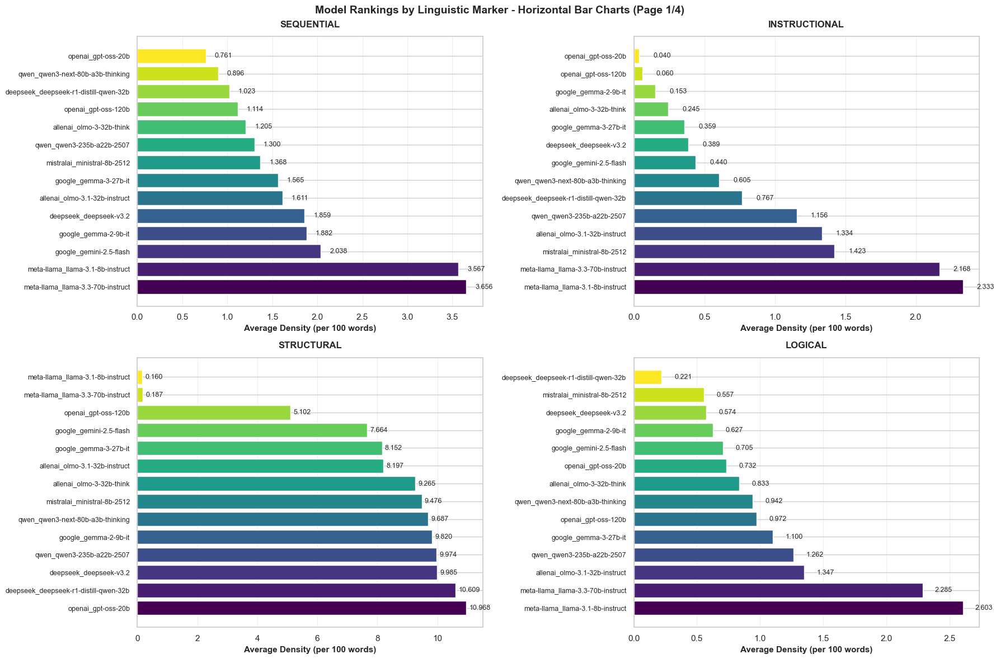

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


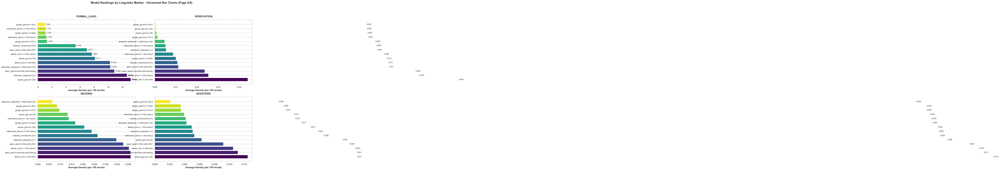

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: The figure layout has changed to tight
  plt.tight_layout()





C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:87: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


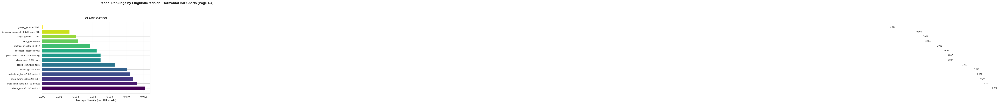


Generating top 5 models per marker (vertical bars)...



C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


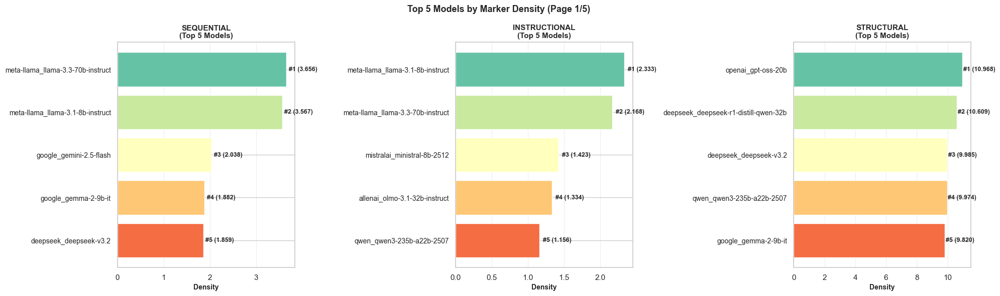

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


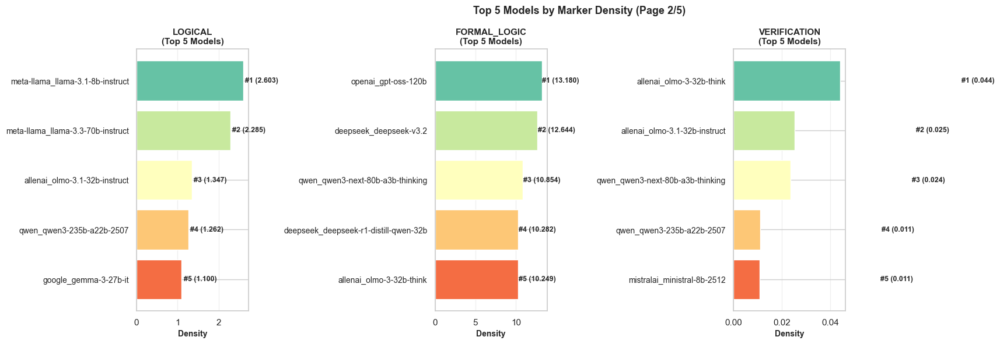

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: Tight layout not applied. tight_layout cannot make Axes width small enough to accommodate all Axes decorations
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


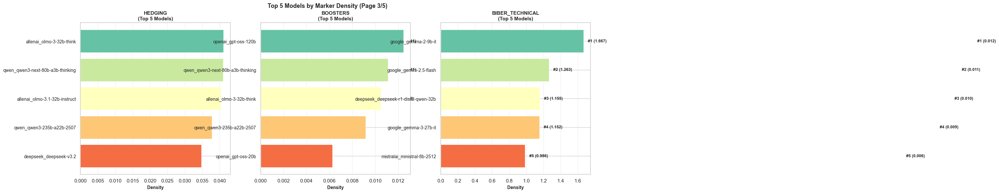

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


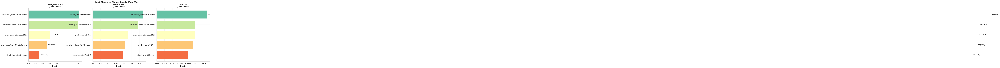

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()
C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:128: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


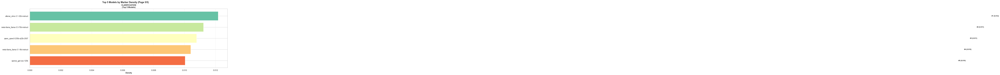


Generating comprehensive model comparison chart...



C:\Users\ASUS\AppData\Local\Temp\ipykernel_23512\2060127443.py:166: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


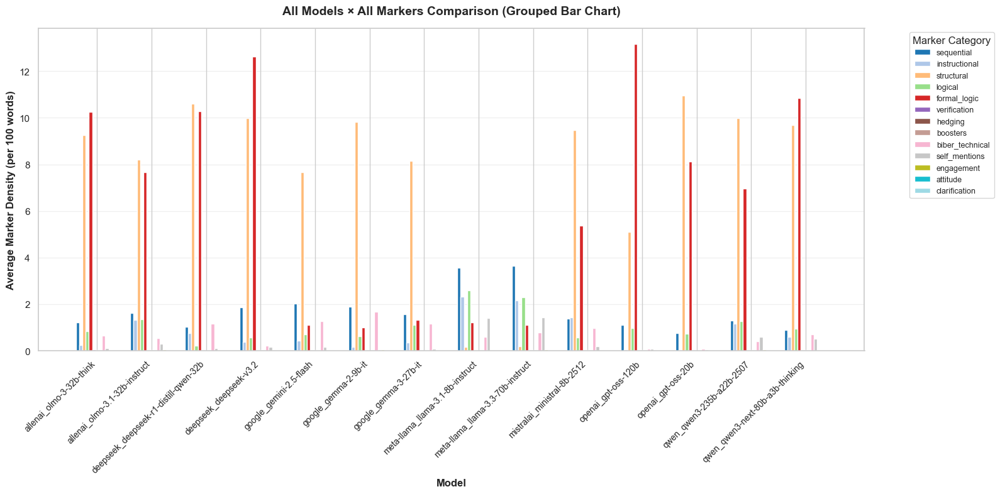


SUMMARY: Model Performance Across All Markers

📊 Average Ranking Position (lower = better overall performance):
    1. qwen_qwen3-235b-a22b-2507                     | Avg Rank:  4.92
    2. allenai_olmo-3.1-32b-instruct                 | Avg Rank:  5.46
    3. meta-llama_llama-3.3-70b-instruct             | Avg Rank:  5.62
    4. meta-llama_llama-3.1-8b-instruct              | Avg Rank:  5.77
    5. qwen_qwen3-next-80b-a3b-thinking              | Avg Rank:  6.23
    6. allenai_olmo-3-32b-think                      | Avg Rank:  6.77
    7. mistralai_ministral-8b-2512                   | Avg Rank:  7.15
    8. google_gemini-2.5-flash                       | Avg Rank:  7.92
    9. deepseek_deepseek-v3.2                        | Avg Rank:  8.15
   10. google_gemma-3-27b-it                         | Avg Rank:  8.85
   11. openai_gpt-oss-120b                           | Avg Rank:  8.92
   12. deepseek_deepseek-r1-distill-qwen-32b         | Avg Rank:  9.23
   13. openai_gpt-oss-20b          

In [17]:
# ===== 13) Bar Chart Visualizations for Model Rankings =====
# Visualisasi ranking model untuk setiap marker category dengan bar chart

# ===== ENSURE ALL REQUIRED VARIABLES ARE DEFINED =====
# (For robustness if this cell is run independently)
if 'marker_categories' not in locals():
    marker_categories = [
        "sequential", "instructional", "structural", "logical",
        "formal_logic", "verification", "hedging", "boosters",
        "biber_technical", "self_mentions", "engagement", "attitude", "clarification",
    ]

if 'density_metrics' not in locals():
    density_metrics = [f"{cat}_density" for cat in marker_categories]

# Verify required dataframes exist
if 'df_agg_5' not in locals() or 'df_agg_3' not in locals():
    print("⚠️ WARNING: Required dataframes (df_agg_5, df_agg_3) not found in memory.")
    print("Please run earlier cells to generate aggregated data.")
    raise NameError("Missing required dataframes: df_agg_5 and/or df_agg_3")

print("\n" + "=" * 140)
print("📊 GENERATING BAR CHART VISUALIZATIONS FOR MODEL RANKINGS")
print("=" * 140)

# Prepare data untuk semua markers
ranking_data_all = []
for marker_cat in marker_categories:
    marker_col = f"{marker_cat}_density"
    model_marker_mean = df_agg_5.groupby("model_name")[marker_col].mean().sort_values(ascending=False)
    
    for rank, (model, value) in enumerate(model_marker_mean.items(), 1):
        ranking_data_all.append({
            "Marker": marker_cat,
            "Model": model,
            "Density": value,
            "Rank": rank
        })

ranking_df_full = pd.DataFrame(ranking_data_all)

# ========== Visualization Option A: Individual Bar Chart per Marker ==========
print("\nGenerating individual bar charts for each marker (4 markers per page)...\n")

models_sorted = sorted(df_agg_5["model_name"].unique())
markers_per_page = 4
n_cols = 2
n_rows = 2

for page_start in range(0, len(marker_categories), markers_per_page):
    page_markers = marker_categories[page_start : page_start + markers_per_page]
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 12), constrained_layout=True)
    axes = np.array(axes).reshape(-1)
    
    for subplot_idx, marker_cat in enumerate(page_markers):
        ax = axes[subplot_idx]
        marker_col = f"{marker_cat}_density"
        
        # Get ranking untuk marker ini
        marker_data = ranking_df_full[ranking_df_full["Marker"] == marker_cat].copy()
        marker_data = marker_data.sort_values("Density", ascending=False)
        
        # Create bar chart
        bars = ax.barh(range(len(marker_data)), marker_data["Density"].values, color=plt.cm.viridis(np.linspace(0, 1, len(marker_data))))
        ax.set_yticks(range(len(marker_data)))
        ax.set_yticklabels(marker_data["Model"].values, fontsize=9)
        ax.set_xlabel("Average Density (per 100 words)", fontsize=11, fontweight="bold")
        ax.set_title(f"{marker_cat.upper()}", fontsize=12, fontweight="bold", pad=12)
        ax.grid(axis="x", alpha=0.3)
        
        # Add value labels on bars
        for i, (idx, row) in enumerate(marker_data.iterrows()):
            ax.text(row["Density"] + 0.1, i, f"{row['Density']:.3f}", va="center", fontsize=9)
    
    # Hide unused subplots
    for idx in range(len(page_markers), len(axes)):
        axes[idx].set_visible(False)
    
    page_no = (page_start // markers_per_page) + 1
    total_pages = int(np.ceil(len(marker_categories) / markers_per_page))
    fig.suptitle(
        f"Model Rankings by Linguistic Marker - Horizontal Bar Charts (Page {page_no}/{total_pages})",
        fontsize=14,
        fontweight="bold",
        y=0.98
    )
    plt.tight_layout()
    plt.show()

# ========== Visualization Option B: Top 5 Models per Marker (Vertical Bar) ==========
print("\nGenerating top 5 models per marker (vertical bars)...\n")

for page_start in range(0, len(marker_categories), 3):
    page_markers = marker_categories[page_start : page_start + 3]
    fig, axes = plt.subplots(1, len(page_markers), figsize=(20, 6), constrained_layout=True)
    
    if len(page_markers) == 1:
        axes = [axes]
    
    for subplot_idx, marker_cat in enumerate(page_markers):
        ax = axes[subplot_idx]
        
        # Get top 5 models
        marker_data = ranking_df_full[ranking_df_full["Marker"] == marker_cat].copy()
        marker_data = marker_data.head(5).sort_values("Density", ascending=True)  # Sort ascending for better visualization
        
        # Create bar chart
        colors_gradient = plt.cm.Spectral(np.linspace(0.2, 0.8, len(marker_data)))
        bars = ax.barh(range(len(marker_data)), marker_data["Density"].values, color=colors_gradient)
        ax.set_yticks(range(len(marker_data)))
        ax.set_yticklabels(marker_data["Model"].values, fontsize=10)
        ax.set_xlabel("Density", fontsize=10, fontweight="bold")
        ax.set_title(f"{marker_cat.upper()}\n(Top 5 Models)", fontsize=11, fontweight="bold")
        ax.grid(axis="x", alpha=0.3)
        
        # Add rank badges
        for i, (idx, row) in enumerate(marker_data.iterrows()):
            rank = row["Rank"]
            ax.text(row["Density"] + 0.05, i, f"#{rank} ({row['Density']:.3f})", va="center", fontsize=9, fontweight="bold")
    
    page_no = (page_start // 3) + 1
    total_pages = int(np.ceil(len(marker_categories) / 3))
    fig.suptitle(
        f"Top 5 Models by Marker Density (Page {page_no}/{total_pages})",
        fontsize=13,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()

# ========== Visualization Option C: All Models Comparison (Box-like view) ==========
print("\nGenerating comprehensive model comparison chart...\n")

fig, ax = plt.subplots(figsize=(16, 8), constrained_layout=True)

# Prepare data for plotting
model_list = sorted(df_agg_5["model_name"].unique())
marker_means = []

for model in model_list:
    model_marker_means = []
    for marker_cat in marker_categories:
        marker_col = f"{marker_cat}_density"
        model_data = df_agg_5[df_agg_5["model_name"] == model]
        mean_val = model_data[marker_col].mean()
        model_marker_means.append(mean_val)
    marker_means.append(model_marker_means)

# Create heatmap-style visualization
x_pos = np.arange(len(model_list))
width = 0.06  # Width of each marker bar
colors_markers = plt.cm.tab20(np.linspace(0, 1, len(marker_categories)))

for i, marker_cat in enumerate(marker_categories):
    values = [marker_means[j][i] for j in range(len(model_list))]
    ax.bar(x_pos + i * width, values, width, label=marker_cat, color=colors_markers[i])

ax.set_xlabel("Model", fontsize=12, fontweight="bold")
ax.set_ylabel("Average Marker Density (per 100 words)", fontsize=12, fontweight="bold")
ax.set_title("All Models × All Markers Comparison (Grouped Bar Chart)", fontsize=14, fontweight="bold", pad=16)
ax.set_xticks(x_pos + width * (len(marker_categories) - 1) / 2)
ax.set_xticklabels(model_list, rotation=45, ha="right", fontsize=10)
ax.legend(title="Marker Category", bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=9, ncol=1)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# ========== Summary Statistics ==========
print("\n" + "=" * 140)
print("SUMMARY: Model Performance Across All Markers")
print("=" * 140)

# Calculate average ranking for each model
model_avg_rank = ranking_df_full.groupby("Model")["Rank"].mean().sort_values()
print("\n📊 Average Ranking Position (lower = better overall performance):")
for rank, (model, avg_rank) in enumerate(model_avg_rank.items(), 1):
    print(f"   {rank:2d}. {model:45s} | Avg Rank: {avg_rank:5.2f}")

print("\n" + "=" * 140)
